# 📊 Desafio NPS — Fase 1 · Parte 3: Análise Exploratória de Dados (EDA)

No ciclo **CRISP-DM**, esta é a etapa de **Entendimento dos Dados**. Antes de pensar em qualquer modelo, precisamos conhecer o material que temos em mãos: o que cada coluna significa, se os dados são confiáveis, como as variáveis se distribuem e como se relacionam com a nossa **variável-alvo (target)**, a nota de NPS.

A postura aqui é a de um(a) **cientista de dados investigador(a)**: observar, questionar, testar e comunicar. E, acima de tudo, **desconfiar primeiro, confiar depois**.

### 🎯 Pergunta de negócio
> *Quais pontos da jornada de compra transformam clientes em detratores, e o que a empresa pode fazer a respeito?*

### ❓ Perguntas analíticas

| Tipo de pergunta | Pergunta |
|---|---|
| **Descritiva** (o que aconteceu?) | Qual é o NPS da empresa? Como os clientes se dividem entre detratores, neutros e promotores? |
| **Diagnóstica** (por que aconteceu?) | Quais fatores da jornada (entrega, atendimento, preço, perfil) estão associados a notas baixas? |
| **Preditiva** (o que pode acontecer?) | Com quais informações seria possível antecipar quem vai virar detrator? *(próximas fases)* |
| **Prescritiva** (o que devemos fazer?) | Que ações tendem a reduzir a proporção de detratores? *(registro final e teste A/B)* |

### 🧪 Hipóteses que vamos colocar à prova

| # | Hipótese | Área |
|---|---|---|
| H1 | O atraso na entrega reduz a nota de NPS | Logística |
| H2 | Mais contatos com o SAC e mais reclamações reduzem a nota | Atendimento |
| H3 | Um tempo de resolução maior reduz a nota | Atendimento |
| H4 | Frete mais caro e desconto menor reduzem a nota | Pricing |
| H5 | A nota é diferente entre as regiões | Logística / Comercial |
| H6 | O perfil do cliente (idade, tempo de relacionamento) influencia a nota | CRM |
| H7 | Clientes com nota mais alta recompram mais em 30 dias | CRM |
| H8 | O CSAT interno e o NPS medem a mesma percepção | Experiência |

### 🗺️ Roteiro
1. Configurações e importação dos dados
2. Reconhecimento da estrutura do dataset
3. Avaliação da qualidade dos dados
4. Estatísticas descritivas e exploração inicial
5. Probabilidade e distribuições nos dados
6. Análise da variável-alvo e intervalos de confiança
7. Relação entre variáveis e descoberta de padrões
8. Testes de hipótese
9. Probabilidade condicional
10. Regressão linear múltipla exploratória
11. Registro das descobertas e hipóteses
12. Storytelling: contando a história com os dados
13. Próximo passo: desenho de um teste A/B

> **Como usar no Colab:** execute as células em ordem (*Ambiente de execução → Executar tudo*). Se o arquivo `desafio_nps_fase_1.csv` ainda não estiver na sessão, a Célula 2 abre a janela de upload.

# 1. ⚙️ Configurações e importação dos dados

In [1]:
# ============================================================
# Célula 1 — Importando as bibliotecas e definindo as configurações
# ============================================================
import os
import warnings
warnings.filterwarnings("ignore")   # esconde avisos de versão para deixar a saída mais limpa

import numpy as np                  # cálculos numéricos
import pandas as pd                 # manipulação de tabelas (DataFrames)
import matplotlib.pyplot as plt     # gráficos
import seaborn as sns               # gráficos estatísticos
from scipy import stats             # distribuições de probabilidade e testes de hipótese

import statsmodels.api as sm                                    # regressão linear (OLS) com o summary()
from statsmodels.stats.proportion import proportion_confint     # intervalo de confiança para proporções (Wilson)
from statsmodels.stats.proportion import proportion_effectsize  # tamanho do efeito para proporções (teste A/B)
from statsmodels.stats.power import NormalIndPower              # cálculo do tamanho de amostra (teste A/B)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score   # métricas de regressão

# Para deixar todas as saídas com os mesmos valores a cada execução (bootstrap usa sorteios)
np.random.seed(42)

# Ajuste visual para os gráficos
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Mostra mais colunas e números com 3 casas decimais nas tabelas
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.3f}".format)

# Cores fixas para as categorias de NPS (as mesmas em todos os gráficos)
cores_nps = {"Detrator": "#E8622C", "Neutro": "#A8A69E", "Promotor": "#2A78D6"}

print("Bibliotecas carregadas! pandas", pd.__version__, "| seaborn", sns.__version__)

Bibliotecas carregadas! pandas 2.2.3 | seaborn 0.13.2


In [2]:
# ============================================================
# Célula 2 — Importando os dados
# ============================================================
# Procura o arquivo na pasta atual (Colab) ou na pasta data/ do repositório
candidatos = ["desafio_nps_fase_1.csv", "../data/desafio_nps_fase_1.csv", "data/desafio_nps_fase_1.csv"]
arquivo = next((c for c in candidatos if os.path.exists(c)), None)

# No Colab, se o arquivo ainda não estiver na sessão, abrimos a janela de upload
if arquivo is None:
    from google.colab import files
    enviado = files.upload()
    arquivo = list(enviado.keys())[0]

# Lê o arquivo CSV para um DataFrame
df = pd.read_csv(arquivo)

# Mostra as 5 primeiras linhas para sentir o formato dos valores
df.head()

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.730,4,39.350,4,2,2,55.530,3,0,4,6.900,0,3,6.500
1,2,20,Sul,1,50002,458.950,2,9.510,10,6,4,28.230,3,0,10,2.400,0,3,0.000
2,3,46,Nordeste,111,50003,507.060,5,42.820,6,6,1,40.990,1,4,5,4.800,0,7,1.500
3,4,52,Centro-Oeste,117,50004,302.190,2,19.580,9,5,2,35.240,3,1,11,5.900,0,4,0.300
4,5,56,Norte,50,50005,253.060,1,29.370,11,13,1,39.320,1,1,0,6.100,0,3,7.900


### 📝 Análise dos resultados


- Cada linha reúne a **jornada completa de um pedido**: perfil do cliente, compra, entrega, atendimento, a nota de NPS e a recompra.
- Já nas primeiras linhas aparece um sinal de alerta: a nota de NPS vem com **casas decimais** (6,9; 2,4; 4,8), mas uma pesquisa de NPS só aceita notas inteiras. O CSAT interno tem o mesmo comportamento. Vamos investigar isso na avaliação de qualidade.

# 2. 🔎 Reconhecimento da estrutura do dataset

Antes de procurar respostas nos dados, precisamos entender **que perguntas eles conseguem responder**: quem é o personagem principal (a unidade de análise), que atributos o descrevem e que parte da realidade ficou de fora.

In [3]:
# ============================================================
# Célula 3 — Tamanho da base, tipos de dado e valores não nulos
# ============================================================
print("Formato da base (linhas, colunas):", df.shape)
print()

# info() mostra, para cada coluna: quantidade de valores não nulos e o tipo de dado
df.info()

Formato da base (linhas, colunas): (2500, 19)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                2500 non-null   int64  
 1   customer_age               2500 non-null   int64  
 2   customer_region            2500 non-null   object 
 3   customer_tenure_months     2500 non-null   int64  
 4   order_id                   2500 non-null   int64  
 5   order_value                2500 non-null   float64
 6   items_quantity             2500 non-null   int64  
 7   discount_value             2500 non-null   float64
 8   payment_installments       2500 non-null   int64  
 9   delivery_time_days         2500 non-null   int64  
 10  delivery_delay_days        2500 non-null   int64  
 11  freight_value              2500 non-null   float64
 12  delivery_attempts          2500 non-null   int64  
 13  c

### 📝 Análise dos resultados


**Análise inicial do dataset**

1. **Quantas linhas existem?** 2.500 linhas.
2. **Quantas colunas existem?** 19 colunas.
3. **Quais colunas são `int64` ou `float64`?** 13 colunas `int64` (IDs, idade, contagens, dias, parcelas e recompra) e 5 `float64` (`order_value`, `discount_value`, `freight_value`, `nps_score` e `csat_internal_score`).
4. **Quais colunas são `object`?** Apenas `customer_region`.
5. **Existem valores `NaN`?** Não. Todas as colunas têm 2.500 valores não nulos.
6. **Qual coluna queremos explicar?** A `nps_score`, nossa **variável-alvo (target)**.

**Observação:** os tipos estão coerentes com o significado de cada coluna. Nenhum número veio armazenado como texto, então não é preciso converter tipos antes da análise.

In [4]:
# ============================================================
# Célula 4 — Unidade de análise: quem é o "personagem principal"?
# ============================================================
# Se cada cliente aparece uma única vez, cada linha é ao mesmo tempo um pedido e um cliente
print("Total de linhas:          ", len(df))
print("Clientes diferentes:      ", df["customer_id"].nunique())
print("Pedidos diferentes:       ", df["order_id"].nunique())

# Quantos pedidos cada cliente tem? (máximo)
pedidos_por_cliente = df.groupby("customer_id")["order_id"].nunique()
print("Máximo de pedidos por cliente:", pedidos_por_cliente.max())

Total de linhas:           2500
Clientes diferentes:       2500
Pedidos diferentes:        2500
Máximo de pedidos por cliente: 1


### 📝 Análise dos resultados


- Existem **2.500 clientes diferentes e 2.500 pedidos diferentes**, e nenhum cliente tem mais de um pedido. Portanto, **cada linha é um pedido de um cliente único**: a nota vale ao mesmo tempo para o pedido e para o cliente.
- **Vantagem:** não há risco de o mesmo cliente aparecer em duplicidade ou, mais adiante, cair ao mesmo tempo no treino e no teste de um modelo.
- **Limitação:** não conseguimos acompanhar o histórico de um cliente ao longo do tempo (por exemplo, se a nota muda depois de uma segunda compra).

## 📘 Dicionário de dados e tipos de variáveis

Classificar corretamente cada variável define **quais estatísticas fazem sentido, quais gráficos usar, quais testes aplicar e como tratar valores ausentes**. Também anotamos **em que momento** cada informação é registrada em relação à pesquisa de NPS: só o que acontece **antes** da pesquisa pode explicar a nota.

| Variável | O que representa | Tipo de variável | Momento em relação à pesquisa |
|---|---|---|---|
| `customer_id` | Identificador do cliente | Identificador (não é quantidade) | — |
| `order_id` | Identificador do pedido | Identificador (não é quantidade) | — |
| `customer_age` | Idade do cliente | Numérica discreta | Antes |
| `customer_region` | Região do cliente | Categórica nominal | Antes |
| `customer_tenure_months` | Tempo de relacionamento (meses) | Numérica discreta | Antes |
| `order_value` | Valor do pedido (R$) | Numérica contínua | Antes |
| `items_quantity` | Quantidade de itens | Numérica discreta | Antes |
| `discount_value` | Desconto aplicado (R$) | Numérica contínua | Antes |
| `payment_installments` | Número de parcelas | Numérica discreta | Antes |
| `delivery_time_days` | Tempo total de entrega (dias) | Numérica discreta | Antes |
| `delivery_delay_days` | Dias de atraso na entrega | Numérica discreta | Antes |
| `freight_value` | Valor do frete (R$) | Numérica contínua | Antes |
| `delivery_attempts` | Tentativas de entrega | Numérica discreta | Antes |
| `customer_service_contacts` | Contatos com o atendimento | Numérica discreta | Incerto |
| `resolution_time_days` | Tempo para resolver problemas (dias) | Numérica discreta | Incerto |
| `complaints_count` | Reclamações registradas | Numérica discreta | Incerto |
| `csat_internal_score` | Score interno de satisfação | Numérica contínua | Incerto |
| `nps_score` | Nota de NPS (0 a 10) — **target** | Numérica, com natureza **ordinal** | Coleta |
| `repeat_purchase_30d` | Recompra em até 30 dias (0/1) | Booleana | **Depois** |

In [5]:
# ============================================================
# Célula 5 — Separando as variáveis por tipo e por momento da jornada
# ============================================================
ids = ["customer_id", "order_id"]           # identificadores: ficam fora das estatísticas
alvo = "nps_score"                           # nossa variável-alvo (target)

# Variáveis numéricas e categóricas, descobertas a partir do próprio DataFrame
numericas = [c for c in df.select_dtypes(include="number").columns if c not in ids]
categoricas = list(df.select_dtypes(exclude="number").columns)

# Momento em que cada variável é registrada em relação à pesquisa de NPS
antes_da_pesquisa = ["customer_age", "customer_tenure_months", "order_value", "items_quantity",
                     "discount_value", "payment_installments", "delivery_time_days",
                     "delivery_delay_days", "freight_value", "delivery_attempts"]
momento_incerto = ["customer_service_contacts", "resolution_time_days", "complaints_count",
                   "csat_internal_score"]
depois_da_pesquisa = ["repeat_purchase_30d"]

print("Variáveis numéricas  :", len(numericas), numericas)
print("Variáveis categóricas:", categoricas)

Variáveis numéricas  : 16 ['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity', 'discount_value', 'payment_installments', 'delivery_time_days', 'delivery_delay_days', 'freight_value', 'delivery_attempts', 'customer_service_contacts', 'resolution_time_days', 'nps_score', 'repeat_purchase_30d', 'complaints_count', 'csat_internal_score']
Variáveis categóricas: ['customer_region']


### 📝 Análise dos resultados


- Para a análise, ficamos com **16 variáveis numéricas** (os dois IDs saem) e **1 categórica nominal** (`customer_region`).
- Atenção a dois casos em que o tipo do Python não conta toda a história:
  - `nps_score` é numérica, mas tem **natureza ordinal**: a distância entre 6 e 7 (de detrator para neutro) não tem o mesmo significado de negócio que a distância entre 3 e 4.
  - `repeat_purchase_30d` é armazenada como número, mas é **booleana** (0 ou 1). A média dela é uma proporção.
- A separação por **momento em relação à pesquisa** será usada nas correlações e na regressão para evitar **vazamento de dados**: a recompra acontece depois da pesquisa e não pode explicar a nota.

## 🧭 A história que os dados conseguem contar

Um dataset nunca mostra a realidade completa, apenas aquilo que foi possível registrar. Antes de tirar conclusões, vale perguntar **quem está incluído e quem não está**:

- **Só quem respondeu à pesquisa** está na base. Pesquisas de satisfação sofrem com **viés de autosseleção**: quem teve uma experiência muito boa ou muito ruim tende a responder mais. Não sabemos nada sobre quem ignorou a pesquisa.
- **Só pedidos concluídos.** Quem desistiu da compra (por exemplo, por causa do frete) não aparece.
- **Não há datas.** Não dá para avaliar tendência, sazonalidade (Black Friday, Natal) nem se o retrato é atual.
- **Não há transportadora, cidade ou centro de distribuição.** A região é o único recorte geográfico.

Esses silêncios não invalidam a análise, mas limitam o que podemos generalizar.

# 3. 🧹 Avaliação da qualidade dos dados

*Garbage in, garbage out*: se os dados estão errados, o resultado final também estará. Avaliamos os pilares de qualidade:

- **Completude:** há dados faltando?
- **Consistência:** os valores fazem sentido entre si?
- **Validade:** os dados seguem as regras do negócio (ex.: nota entre 0 e 10)?
- **Precisão:** o valor registrado é fiel à realidade?
- **Atualidade:** o dado ainda é relevante?

In [6]:
# ============================================================
# Célula 6 — Completude: há valores faltantes?
# ============================================================
# Conta quantos valores ausentes existem em cada coluna
faltantes = df.isnull().sum()
print("Total de valores faltantes na base:", faltantes.sum())
faltantes

Total de valores faltantes na base: 0


customer_id                  0
customer_age                 0
customer_region              0
customer_tenure_months       0
order_id                     0
order_value                  0
items_quantity               0
discount_value               0
payment_installments         0
delivery_time_days           0
delivery_delay_days          0
freight_value                0
delivery_attempts            0
customer_service_contacts    0
resolution_time_days         0
nps_score                    0
repeat_purchase_30d          0
complaints_count             0
csat_internal_score          0
dtype: int64

### 📝 Análise dos resultados


- **Completude atendida:** nenhuma das 19 colunas tem valores faltantes.
- Isso é **incomum em pesquisas reais**, em que sempre há clientes que não respondem ou campos em branco. A base completa sugere que os não respondentes foram excluídos antes ou que os dados foram preparados (ou simulados) para o desafio.
- **Consequência:** não precisamos imputar valores (como preencher com a mediana), mas precisamos lembrar que **não sabemos nada sobre quem não respondeu**.

In [7]:
# ============================================================
# Célula 7 — Nulos "disfarçados" e padronização da variável categórica
# ============================================================
# Textos como "–", "?" ou "NA" escondem valores ausentes; grafias diferentes ("Sul", "sul") dividem categorias
print("Categorias de customer_region:", df["customer_region"].unique())
print()

# dropna=False faz com que os valores ausentes também apareçam na contagem
df["customer_region"].value_counts(dropna=False)

Categorias de customer_region: ['Nordeste' 'Sul' 'Centro-Oeste' 'Norte' 'Sudeste']



customer_region
Sul             521
Sudeste         520
Norte           506
Nordeste        485
Centro-Oeste    468
Name: count, dtype: int64

### 📝 Análise dos resultados


- `customer_region` tem **5 categorias**, todas escritas de forma padronizada, sem variações como "sul"/"Sul" e **sem nulos disfarçados** (como "–" ou "?").
- As regiões estão bem equilibradas, entre 468 (Centro-Oeste) e 521 pedidos (Sul). Isso permite comparar as regiões entre si com segurança.

In [8]:
# ============================================================
# Célula 8 — Duplicados
# ============================================================
# Linhas idênticas em todas as colunas
print("Linhas duplicadas (todas as colunas):", df.duplicated().sum())

# Linhas idênticas ignorando os IDs (o mesmo pedido registrado com outro identificador)
print("Linhas duplicadas ignorando os IDs:  ", df.drop(columns=ids).duplicated().sum())

Linhas duplicadas (todas as colunas): 0
Linhas duplicadas ignorando os IDs:   0


### 📝 Análise dos resultados


- **Nenhuma linha duplicada**, nem considerando todas as colunas, nem ignorando os IDs.
- **Unicidade atendida:** nenhum pedido foi registrado duas vezes, então não há nada a remover.

In [9]:
# ============================================================
# Célula 9 — Validade: os valores respeitam as regras do negócio?
# ============================================================
print("Valores negativos em colunas numéricas:", (df[numericas] < 0).sum().sum())
print("nps_score fora de 0 a 10:              ", (~df["nps_score"].between(0, 10)).sum())
print("csat_internal_score fora de 0 a 10:    ", (~df["csat_internal_score"].between(0, 10)).sum())
print("repeat_purchase_30d diferente de 0/1:  ", (~df["repeat_purchase_30d"].isin([0, 1])).sum())
print()

# Mínimo e máximo de cada variável numérica: o menor e o maior valor fazem sentido?
df[numericas].describe().loc[["min", "max"]].T

Valores negativos em colunas numéricas: 0
nps_score fora de 0 a 10:               0
csat_internal_score fora de 0 a 10:     0
repeat_purchase_30d diferente de 0/1:   0



,min,max
customer_age,18.000,69.000
customer_tenure_months,1.000,119.000
order_value,7.760,1983.810
items_quantity,1.000,6.000
discount_value,0.020,230.330
payment_installments,1.000,11.000
delivery_time_days,2.000,14.000
delivery_delay_days,0.000,8.000
freight_value,2.620,76.130
delivery_attempts,1.000,3.000


### 📝 Análise dos resultados


- **Validade atendida:** não há valores negativos, e a nota, o CSAT e a recompra estão dentro dos domínios esperados (0 a 10 e 0/1).
- Os mínimos e máximos fazem sentido no negócio: idade de 18 a 69 anos, relacionamento de 1 a 119 meses, pedido de R$ 7,76 a R$ 1.983,81, frete de R$ 2,62 a R$ 76,13, entrega de 2 a 14 dias e atraso de 0 a 8 dias.
- **Ponto de atenção:** os limites são "redondos" demais (idade exatamente entre 18 e 69, relacionamento sempre abaixo de 10 anos, entrega entre 2 e 14 dias). Parecem **regras usadas para gerar os dados**, e não limites naturais de uma operação real.

In [10]:
# ============================================================
# Célula 10 — Consistência: regras que cruzam colunas
# ============================================================
# Uma pesquisa de NPS só aceita notas inteiras (0, 1, 2, ..., 10)
nota_com_decimal = df["nps_score"] % 1 != 0

# O atraso deveria fazer parte do tempo total de entrega
atraso_maior_que_entrega = df["delivery_delay_days"] > df["delivery_time_days"]

# Reclamação ou tempo de resolução sem nenhum contato com o atendimento
reclamacao_sem_contato = (df["complaints_count"] > 0) & (df["customer_service_contacts"] == 0)
resolucao_sem_contato = (df["resolution_time_days"] > 0) & (df["customer_service_contacts"] == 0)

# Desconto maior do que o próprio valor do pedido
desconto_maior_que_pedido = df["discount_value"] > df["order_value"]

consistencia = pd.DataFrame({
    "registros": [nota_com_decimal.sum(), atraso_maior_que_entrega.sum(), reclamacao_sem_contato.sum(),
                  resolucao_sem_contato.sum(), desconto_maior_que_pedido.sum()]
}, index=["Nota de NPS com casas decimais",
          "Atraso maior que o tempo total de entrega",
          "Reclamações sem nenhum contato com o SAC",
          "Tempo de resolução sem nenhum contato com o SAC",
          "Desconto maior que o valor do pedido"])
consistencia["% da base"] = consistencia["registros"] / len(df) * 100
consistencia

,registros,% da base
Nota de NPS com casas decimais,2075,83.000
Atraso maior que o tempo total de entrega,121,4.840
Reclamações sem nenhum contato com o SAC,531,21.240
Tempo de resolução sem nenhum contato com o SAC,511,20.440
Desconto maior que o valor do pedido,35,1.400


### 📝 Análise dos resultados


As regras que cruzam colunas revelam o que `describe()` não mostra:

| Regra violada | Registros | Leitura |
|---|---|---|
| Nota de NPS com casas decimais | 2.075 (83,0%) | A pesquisa só aceita inteiros: a nota foi transformada ou simulada. Isso exige uma **regra de corte** para classificar detratores (Seção 6). |
| Atraso maior que o tempo total de entrega | 121 (4,8%) | Só faz sentido se `delivery_time_days` **não incluir** o atraso. É uma dúvida de definição a validar com o negócio. |
| Reclamações sem nenhum contato com o SAC | 531 (21,2%) | As reclamações podem vir de outro canal (redes sociais, sites de reputação), ou as colunas foram geradas de forma independente. |
| Tempo de resolução sem contato com o SAC | 511 (20,4%) | Mesmo problema: há "resolução" de algo que não foi aberto no atendimento. |
| Desconto maior que o valor do pedido | 35 (1,4%) | Pode indicar que `order_value` já é o valor líquido (depois do desconto) ou um erro de registro. |

In [11]:
# ============================================================
# Célula 11 — Os registros inconsistentes distorcem a nota?
# ============================================================
# Marcamos (sem apagar!) os pedidos com alguma inconsistência estrutural
df["flag_inconsistencia"] = (atraso_maior_que_entrega | reclamacao_sem_contato
                             | desconto_maior_que_pedido).astype(int)

print(f"Pedidos com alguma inconsistência: {df['flag_inconsistencia'].sum()} "
      f"({df['flag_inconsistencia'].mean():.1%} da base)")

# Compara a nota de NPS entre os pedidos com e sem inconsistência
df.groupby("flag_inconsistencia")["nps_score"].describe()

Pedidos com alguma inconsistência: 651 (26.0% da base)


,count,mean,std,min,25%,50%,75%,max
flag_inconsistencia,,,,,,,,
0,1849.000,4.214,2.460,0.000,2.400,4.200,6.000,10.000
1,651.000,4.846,2.592,0.000,3.000,4.900,6.700,10.000


### 📝 Análise dos resultados


- **651 pedidos (26,0% da base)** têm alguma inconsistência estrutural.
- Esses pedidos têm nota um pouco **maior**: média de 4,85 contra 4,21 e mediana de 4,9 contra 4,2.
- A diferença tem uma explicação mecânica: o maior grupo de inconsistência é "reclamação sem contato com o SAC". Esses pedidos, por definição, têm **zero contatos com o SAC**, e quem não acionou o SAC dá notas mais altas (Seção 7.3). Ou seja, a flag está capturando o efeito do atendimento, e não um erro que distorça a nota.

**Decidindo o que fazer com os erros**

| Problema | Decisão | Motivo |
|---|---|---|
| Notas com decimais | Manter e definir uma regra de corte, testando a sensibilidade | Remover apagaria 83% da base |
| Registros inconsistentes (26%) | Manter e marcar com `flag_inconsistencia` | Apagar 26% enviesaria a amostra para quem acionou o SAC |
| Dúvidas de definição | Registrar como perguntas para a área de negócio | Só quem conhece o processo pode dizer qual é a regra correta |

Nada foi apagado ou "embelezado": cada decisão está documentada para garantir rastreabilidade.

# 4. 📈 Estatísticas descritivas e exploração inicial

Agora queremos enxergar o comportamento do dataset como um todo: **centro** (média e mediana), **dispersão** (desvio padrão, quartis) e **forma** (assimetria). Algumas perguntas guiam a leitura:

- A distribuição é muito assimétrica?
- Existem grupos com características extremas?
- Os valores mínimo e máximo fazem sentido no contexto do negócio?

In [12]:
# ============================================================
# Célula 12 — Estatísticas descritivas das variáveis numéricas
# ============================================================
# describe() entrega: count, média (mean), desvio padrão (std), mínimo, quartis (25%, 50%, 75%) e máximo
resumo = df[numericas].describe().T

# Acrescentamos a mediana e a assimetria (skew): > 0 indica cauda à direita (média > mediana)
resumo["mediana"] = df[numericas].median()
resumo["assimetria"] = df[numericas].skew()
resumo[["count", "mean", "mediana", "std", "min", "25%", "75%", "max", "assimetria"]]

,count,mean,mediana,std,min,25%,75%,max,assimetria
customer_age,2500.000,43.396,43.000,14.888,18.000,31.000,56.000,69.000,0.001
customer_tenure_months,2500.000,61.322,62.000,34.479,1.000,31.000,91.000,119.000,-0.046
order_value,2500.000,434.260,375.515,289.772,7.760,220.245,577.290,1983.810,1.270
items_quantity,2500.000,3.471,3.000,1.687,1.000,2.000,5.000,6.000,0.034
discount_value,2500.000,29.746,20.935,29.226,0.020,8.885,40.832,230.330,1.872
payment_installments,2500.000,6.004,6.000,3.160,1.000,3.000,9.000,11.000,0.018
delivery_time_days,2500.000,8.022,8.000,3.770,2.000,5.000,11.000,14.000,-0.018
delivery_delay_days,2500.000,2.187,2.000,1.454,0.000,1.000,3.000,8.000,0.595
freight_value,2500.000,38.217,38.500,12.076,2.620,29.928,46.270,76.130,-0.024
delivery_attempts,2500.000,2.006,2.000,0.815,1.000,1.000,3.000,3.000,-0.010


### 📝 Análise dos resultados


- **Cliente e pedido típicos:** cliente de 43 anos, com cerca de 5 anos de relacionamento (mediana de 62 meses), pedido de **R$ 375,52 (mediana)**, 3 itens, 6 parcelas, frete de R$ 38,50 e entrega em 8 dias.
- **A distribuição é muito assimétrica?** Sim, em duas variáveis de valor: `order_value` (média de R$ 434,26 contra mediana de R$ 375,52; assimetria 1,27) e `discount_value` (média de R$ 29,75 contra mediana de R$ 20,94; assimetria 1,87). São casos de **assimetria positiva**: poucos pedidos com valores altos puxam a média para cima. Para descrever o "pedido típico", a **mediana** é melhor que a média.
- **Existem grupos com características extremas?** Os contatos com o SAC (assimetria 0,77) e o atraso (0,60) têm cauda à direita: a maioria tem poucos eventos, e um grupo menor tem muitos.
- **O mínimo faz sentido?** Sim (ver Célula 9).
- **Alvo:** nota média de **4,38** e mediana de **4,40**, ambas bem abaixo de 7 (limite de detrator). O CSAT interno é ainda mais baixo (média de 2,94).
- **Recompra:** a média de 0,087 significa que **8,7% dos clientes recompraram** em 30 dias.

                 pedidos      %
customer_region                
Sul                  521 20.840
Sudeste              520 20.800
Norte                506 20.240
Nordeste             485 19.400
Centro-Oeste         468 18.720


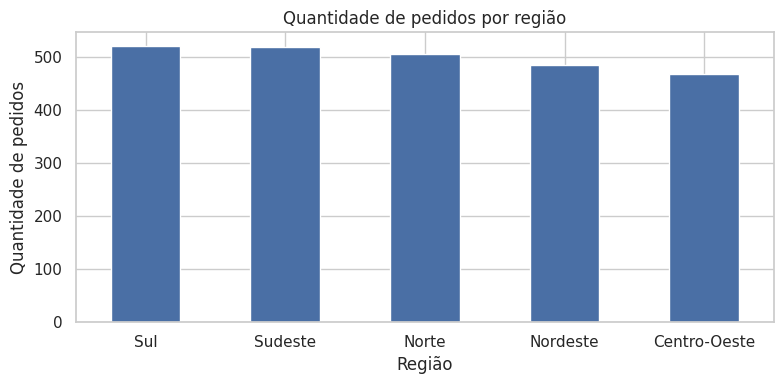

In [13]:
# ============================================================
# Célula 13 — Frequência da variável categórica (região)
# ============================================================
# value_counts() conta quantos pedidos existem em cada região; normalize=True mostra a proporção
regiao = pd.DataFrame({
    "pedidos": df["customer_region"].value_counts(),
    "%": df["customer_region"].value_counts(normalize=True) * 100,
})
print(regiao)

# Gráfico de barras: comparação entre categorias
df["customer_region"].value_counts().plot(kind="bar", figsize=(8, 4), color="#4A6FA5")
plt.title("Quantidade de pedidos por região")
plt.xlabel("Região")
plt.ylabel("Quantidade de pedidos")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- As cinco regiões têm participação parecida, entre **18,7% (Centro-Oeste) e 20,8% (Sul)**.
- Nenhuma categoria domina a base, então nenhuma região vai "puxar" sozinha as conclusões. Todas têm mais de 460 pedidos, tamanho suficiente para comparações.

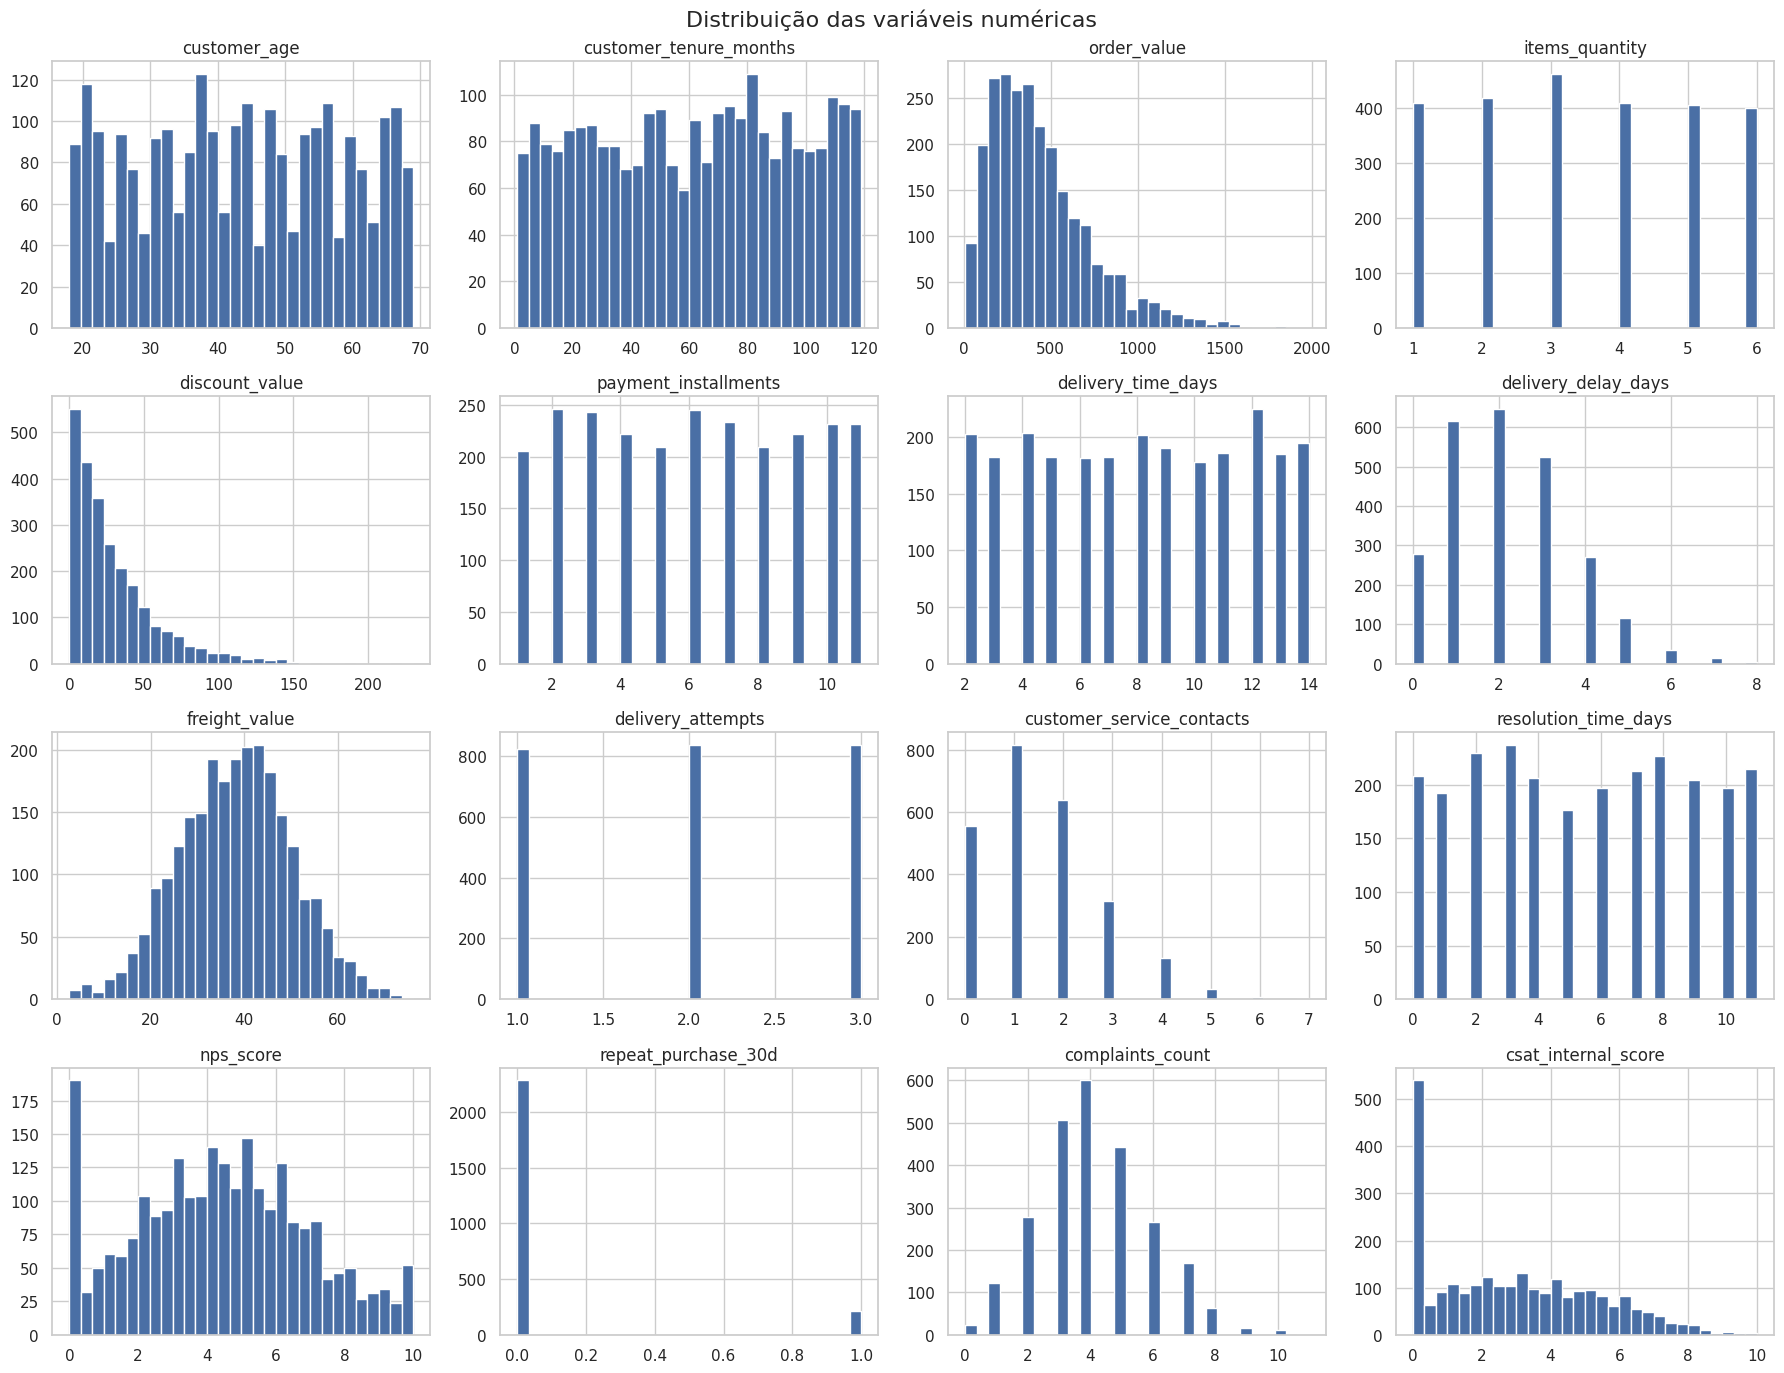

In [14]:
# ============================================================
# Célula 14 — Conhecendo a distribuição de todas as variáveis numéricas
# ============================================================
# Um histograma por variável: mostra onde os valores se concentram, assimetrias e caudas longas
df[numericas].hist(bins=30, figsize=(18, 14), color="#4A6FA5", edgecolor="white")
plt.suptitle("Distribuição das variáveis numéricas", fontsize=16)
plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


Os histogramas revelam formas bem diferentes:

| Forma | Variáveis | Leitura |
|---|---|---|
| **Uniforme** (barras de mesma altura) | idade, tempo de relacionamento, itens, parcelas, tempo de entrega, tentativas de entrega, tempo de resolução | Todos os valores aparecem com a mesma frequência |
| **Contagens de eventos** | atraso, contatos com o SAC, reclamações | Valores inteiros com cauda à direita; atraso e contatos têm o formato de Poisson (Seção 5) |
| **Sino (aproximadamente normal)** | frete | Simétrico em torno de R$ 38 |
| **Assimetria positiva** | valor do pedido, desconto | Muitos valores baixos e uma cauda longa de valores altos |
| **Picos nos extremos** | NPS (pico em 0), CSAT (pico em 0) | A nota parece "cortada" nos limites da escala |
| **Binária** | recompra | Duas barras: 0 e 1 |

As "barras com espaços" nas variáveis discretas são esperadas: elas só assumem valores inteiros. Em uma operação real, seria estranho ter idade, número de itens e parcelas perfeitamente uniformes. É mais um **sinal de base simulada**.

In [15]:
# ============================================================
# Célula 15 — Outliers pela regra do IQR
# ============================================================
# Um valor é considerado outlier se estiver abaixo de Q1 − 1,5×IQR ou acima de Q3 + 1,5×IQR (IQR = Q3 − Q1)
q1 = df[numericas].quantile(0.25)
q3 = df[numericas].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = ((df[numericas] < limite_inferior) | (df[numericas] > limite_superior)).sum()
tabela_outliers = pd.DataFrame({"outliers": outliers,
                                "% da base": outliers / len(df) * 100,
                                "limite_superior": limite_superior,
                                "máximo": df[numericas].max()})
tabela_outliers[tabela_outliers["outliers"] > 0].sort_values("outliers", ascending=False)

,outliers,% da base,limite_superior,máximo
repeat_purchase_30d,218,8.720,0.000,1.000
customer_service_contacts,176,7.040,3.500,7.000
discount_value,125,5.000,88.754,230.330
order_value,84,3.360,1112.857,1983.810
complaints_count,29,1.160,8.000,11.000
delivery_delay_days,17,0.680,6.000,8.000
freight_value,12,0.480,70.784,76.130


### 📝 Análise dos resultados


- **Contatos com o SAC:** 176 pedidos (7,0%) com 4 ou mais contatos.
- **Desconto:** 125 pedidos (5,0%) acima de R$ 88,75.
- **Valor do pedido:** 84 pedidos (3,4%) acima de R$ 1.112,86.
- **Reclamações:** 29 pedidos (1,2%) com 9 ou mais.
- **Atraso:** 17 pedidos (0,7%) com 7 ou 8 dias.
- **Frete:** 12 pedidos (0,5%) acima de R$ 70,78.
- Em `repeat_purchase_30d`, os 218 "outliers" são apenas a **classe rara** (quem recomprou), não valores anômalos.

**Decisão:** manter todos. São valores **plausíveis** no negócio e, em alguns casos, são justamente os eventos que mais interessam: os pedidos com 7 ou 8 dias de atraso são as piores experiências da base.

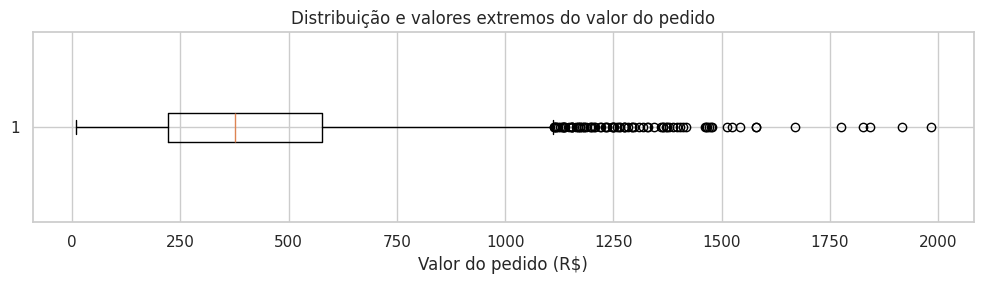

,order_id,order_value,items_quantity,discount_value,nps_score
211,50212,1983.810,5,48.500,6.500
445,50446,1915.890,4,37.400,4.100
1342,51343,1842.300,1,6.680,0.000
1898,51899,1826.220,2,58.330,8.900
2140,52141,1775.080,2,39.880,4.900
1917,51918,1668.290,4,6.110,4.800
1743,51744,1579.630,6,28.000,0.200
2370,52371,1578.500,2,46.190,2.100
2439,52440,1541.740,3,30.640,8.000
229,50230,1522.940,3,24.330,3.600


In [16]:
# ============================================================
# Célula 16 — Investigando os valores extremos do valor do pedido
# ============================================================
# O boxplot ajuda a visualizar: mediana, quartis, dispersão e possíveis valores extremos
plt.figure(figsize=(10, 3))
plt.boxplot(df["order_value"], vert=False)
plt.title("Distribuição e valores extremos do valor do pedido")
plt.xlabel("Valor do pedido (R$)")
plt.tight_layout()
plt.show()

# Os 10 pedidos mais caros: são erros de digitação ou compras grandes plausíveis?
df.sort_values("order_value", ascending=False)[["order_id", "order_value", "items_quantity",
                                                "discount_value", "nps_score"]].head(10)

### 📝 Análise dos resultados


- O boxplot mostra a caixa (50% centrais dos pedidos) entre cerca de R$ 220 e R$ 577, com mediana em torno de R$ 376, e uma sequência de pontos acima de R$ 1.113.
- Os 10 pedidos mais caros vão de R$ 1.522,94 a R$ 1.983,81, com 1 a 6 itens e descontos normais. São **compras maiores plausíveis**, não erros de digitação.
- As notas desses pedidos variam de 0 a 8,9: um valor alto não está associado nem a notas boas nem a notas ruins.
- **Decisão:** manter. Na modelagem, uma transformação (como o log) ou um modelo robusto pode reduzir a influência da cauda.

# 5. 🎲 Probabilidade e distribuições nos dados

Toda distribuição responde a perguntas como *qual o valor mais esperado?* e *qual a variabilidade?*. Reconhecer a distribuição de cada variável ajuda a escolher estatísticas e testes, e às vezes revela **como os dados foram gerados**:

- **Contagem de eventos** → Poisson
- **Sucesso/fracasso** → Binomial
- **Todos os valores igualmente prováveis** → Uniforme
- **Fenômeno "natural", simétrico em torno da média** → Normal

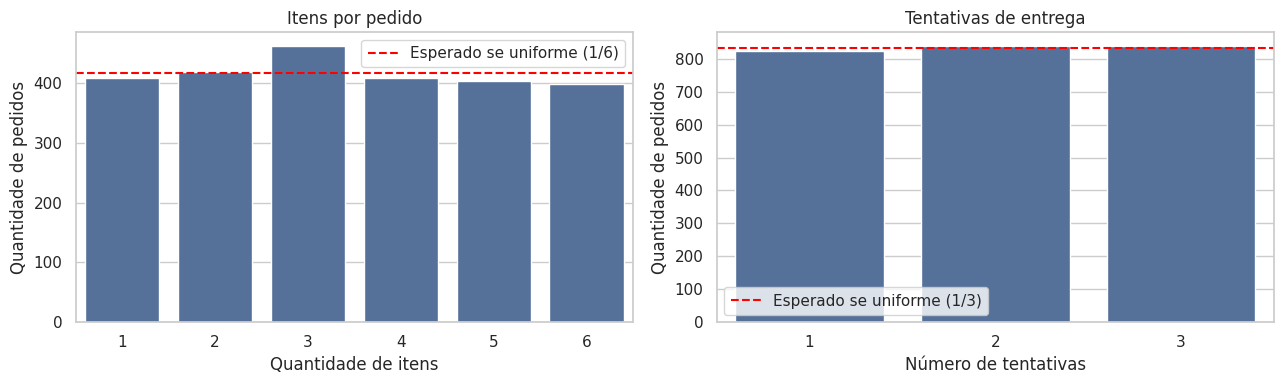

Itens por pedido (frequência relativa):
items_quantity
1   0.164
2   0.167
3   0.185
4   0.163
5   0.162
6   0.160
Name: proportion, dtype: float64


In [17]:
# ============================================================
# Célula 17 — Distribuição uniforme: itens no pedido e tentativas de entrega
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Itens por pedido: se for uniforme, cada valor de 1 a 6 aparece em ~1/6 dos pedidos
sns.countplot(x=df["items_quantity"], color="#4A6FA5", ax=axes[0])
axes[0].axhline(len(df) / 6, color="red", linestyle="--", label="Esperado se uniforme (1/6)")
axes[0].set_title("Itens por pedido")
axes[0].set_xlabel("Quantidade de itens")
axes[0].set_ylabel("Quantidade de pedidos")
axes[0].legend()

# Tentativas de entrega: se for uniforme, cada valor de 1 a 3 aparece em ~1/3 dos pedidos
sns.countplot(x=df["delivery_attempts"], color="#4A6FA5", ax=axes[1])
axes[1].axhline(len(df) / 3, color="red", linestyle="--", label="Esperado se uniforme (1/3)")
axes[1].set_title("Tentativas de entrega")
axes[1].set_xlabel("Número de tentativas")
axes[1].set_ylabel("Quantidade de pedidos")
axes[1].legend()
plt.tight_layout()
plt.show()

# Probabilidade ≈ frequência relativa de cada valor
print("Itens por pedido (frequência relativa):")
print(df["items_quantity"].value_counts(normalize=True).sort_index().round(3))

### 📝 Análise dos resultados


- **Itens por pedido:** cada quantidade de 1 a 6 aparece em 16% a 18,5% dos pedidos, muito perto do esperado se fosse uniforme (1/6 = 16,7%).
- **Tentativas de entrega:** 824, 838 e 838 pedidos com 1, 2 e 3 tentativas, praticamente 1/3 cada.
- Aqui a **probabilidade ≈ frequência relativa**: a chance de um pedido ter 3 itens é de cerca de 1/6.
- **Leitura crítica:** em um e-commerce real, a maioria dos pedidos tem 1 item e a maioria das entregas acontece na primeira tentativa. Distribuições uniformes tão perfeitas reforçam a hipótese de **dados simulados**.

delivery_delay_days: média = 2.19 | variância = 2.12
customer_service_contacts: média = 1.52 | variância = 1.52


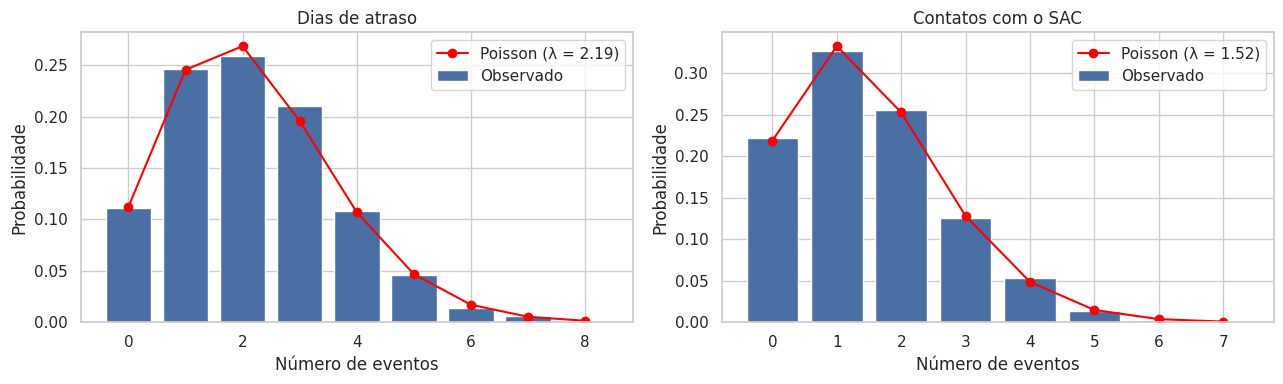

In [18]:
# ============================================================
# Célula 18 — Distribuição de Poisson: atraso e contatos com o SAC
# ============================================================
# Poisson modela o número de vezes que um evento ocorre, com taxa média λ (lambda).
# Assinatura da Poisson: média ≈ variância.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, coluna, titulo in zip(axes,
                              ["delivery_delay_days", "customer_service_contacts"],
                              ["Dias de atraso", "Contatos com o SAC"]):
    lambda_ = df[coluna].mean()                                         # taxa média de ocorrência
    x = np.arange(0, df[coluna].max() + 1)
    prob_poisson = stats.poisson.pmf(x, lambda_)                        # probabilidade teórica de cada valor
    freq_observada = df[coluna].value_counts(normalize=True).sort_index()   # frequência observada

    ax.bar(freq_observada.index, freq_observada.values, color="#4A6FA5", label="Observado")
    ax.plot(x, prob_poisson, color="red", marker="o", label=f"Poisson (λ = {lambda_:.2f})")
    ax.set_title(titulo)
    ax.set_xlabel("Número de eventos")
    ax.set_ylabel("Probabilidade")
    ax.legend()
    print(f"{coluna}: média = {df[coluna].mean():.2f} | variância = {df[coluna].var():.2f}")

plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- **Atraso:** média de 2,19 e variância de 2,12. **Contatos com o SAC:** média e variância iguais a 1,52. Média ≈ variância é a **assinatura da distribuição de Poisson**.
- As curvas teóricas da Poisson (pontos vermelhos) coincidem quase perfeitamente com as barras observadas.
- **Interpretação:** os atrasos e os contatos se comportam como eventos independentes que ocorrem a uma taxa média constante (λ). Com isso, é possível responder perguntas como "qual a chance de um pedido não atrasar?": cerca de 11%.
- **Leitura crítica:** um ajuste tão perfeito é raro em dados reais. É mais um indício de que os dados foram gerados por regras estatísticas.

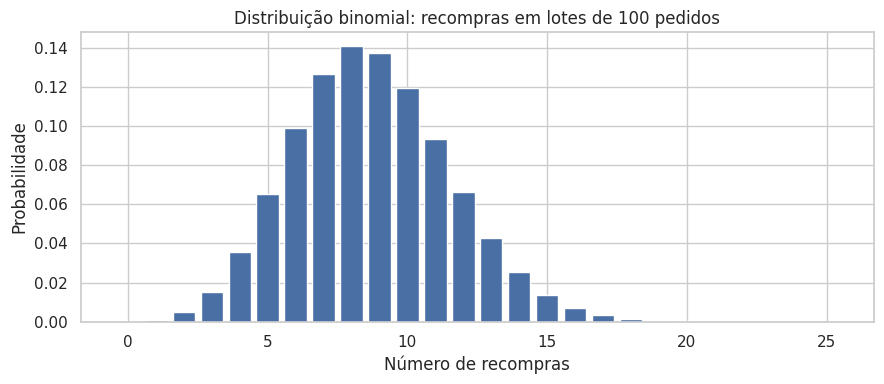

Probabilidade de recompra por pedido: p = 0.087
Recompras esperadas em 100 pedidos: 8.7
Probabilidade de 15 ou mais recompras em 100 pedidos: 0.027


In [19]:
# ============================================================
# Célula 19 — Distribuição binomial: recompra em 30 dias
# ============================================================
# Cada pedido é uma "tentativa" com duas saídas: recomprou (sucesso) ou não (fracasso)
p = df["repeat_purchase_30d"].mean()    # probabilidade de sucesso
n = 100                                  # número de tentativas (um lote de 100 pedidos)
x = np.arange(0, 26)

# stats.binom.pmf calcula a probabilidade de exatamente x recompras em n pedidos
prob = stats.binom.pmf(x, n, p)

plt.figure(figsize=(9, 4))
plt.bar(x, prob, color="#4A6FA5")
plt.title("Distribuição binomial: recompras em lotes de 100 pedidos")
plt.xlabel("Número de recompras")
plt.ylabel("Probabilidade")
plt.tight_layout()
plt.show()

print(f"Probabilidade de recompra por pedido: p = {p:.3f}")
print(f"Recompras esperadas em 100 pedidos: {n * p:.1f}")
print(f"Probabilidade de 15 ou mais recompras em 100 pedidos: {1 - stats.binom.cdf(14, n, p):.3f}")

### 📝 Análise dos resultados


- A probabilidade de recompra por pedido é **p = 0,087 (8,7%)**. Em um lote de 100 pedidos, esperamos em média **8,7 recompras**.
- A distribuição binomial mostra que valores entre 5 e 12 recompras são os mais comuns, e que **15 ou mais recompras em 100 pedidos teriam só 2,7% de chance**.
- **Uso no negócio:** esse tipo de cálculo ajuda a monitorar campanhas. Um lote com 15 ou mais recompras seria um resultado incomum, que merece investigação.
- **Cuidado:** a binomial supõe que cada pedido é independente e tem a mesma chance de recompra. A Seção 7.6 mostra que, nesta base, a recompra depende totalmente da nota.

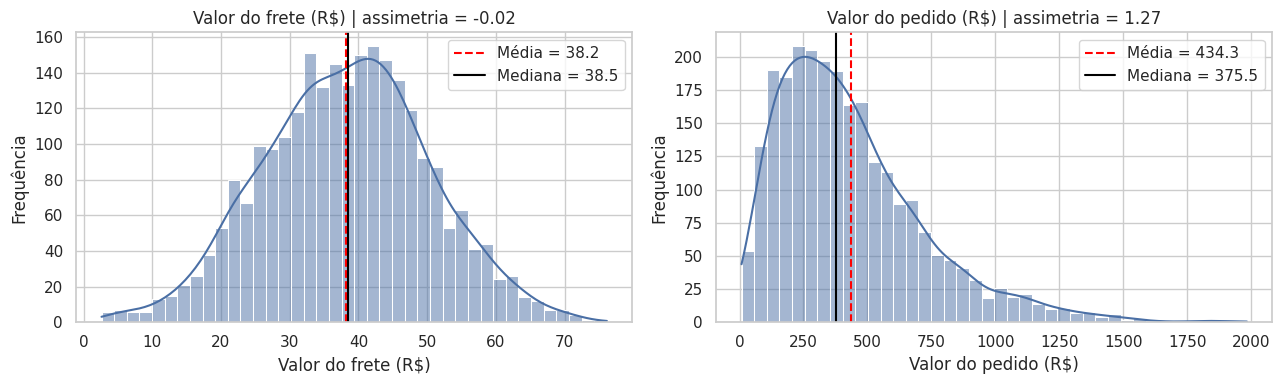

In [20]:
# ============================================================
# Célula 20 — Distribuição normal × assimetria positiva
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, coluna, titulo in zip(axes, ["freight_value", "order_value"],
                              ["Valor do frete (R$)", "Valor do pedido (R$)"]):
    sns.histplot(df[coluna], bins=40, kde=True, color="#4A6FA5", ax=ax)
    ax.axvline(df[coluna].mean(), color="red", linestyle="--", label=f"Média = {df[coluna].mean():.1f}")
    ax.axvline(df[coluna].median(), color="black", linestyle="-", label=f"Mediana = {df[coluna].median():.1f}")
    ax.set_title(f"{titulo} | assimetria = {df[coluna].skew():.2f}")
    ax.set_xlabel(titulo)
    ax.set_ylabel("Frequência")
    ax.legend()

plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- **Frete:** média de R$ 38,2 e mediana de R$ 38,5 praticamente iguais, e assimetria de −0,02. A curva tem o formato de **sino**: comportamento aproximadamente **normal**.
- **Valor do pedido:** média de R$ 434,3 **maior** que a mediana de R$ 375,5, e assimetria de 1,27. É uma **assimetria positiva (à direita)**: a maioria dos pedidos está concentrada à esquerda, e poucos pedidos caros formam uma cauda longa.
- **Regra prática:** em distribuições assimétricas, a **mediana** representa melhor o valor típico, e a média deve ser lida com cuidado.

# 6. 🎯 Análise da variável-alvo: `nps_score`

Olhamos a nota de três formas: como **distribuição** (forma e normalidade), como **categorias de NPS** (detrator, neutro, promotor) e como **indicador agregado** (% de promotores − % de detratores), sempre acompanhado do **intervalo de confiança**, que mostra a incerteza da estimativa.

count   2500.000
mean       4.379
std        2.510
min        0.000
25%        2.600
50%        4.400
75%        6.100
max       10.000
Name: nps_score, dtype: float64

Notas com casas decimais: 83.0%
Notas exatamente iguais a 0:  158
Notas exatamente iguais a 10: 42


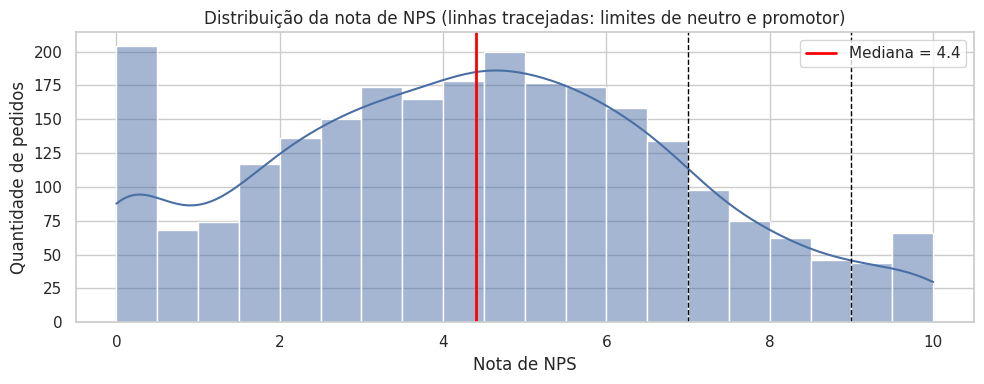

In [21]:
# ============================================================
# Célula 21 — Distribuição da nota de NPS
# ============================================================
print(df["nps_score"].describe())
print()
print("Notas com casas decimais:", f"{(df['nps_score'] % 1 != 0).mean():.1%}")
print("Notas exatamente iguais a 0: ", (df["nps_score"] == 0).sum())
print("Notas exatamente iguais a 10:", (df["nps_score"] == 10).sum())

plt.figure(figsize=(10, 4))
sns.histplot(df["nps_score"], bins=np.arange(0, 10.5, 0.5), kde=True, color="#4A6FA5")
plt.axvline(7, color="black", linestyle="--", linewidth=1)      # a partir de 7: neutro
plt.axvline(9, color="black", linestyle="--", linewidth=1)      # a partir de 9: promotor
plt.axvline(df["nps_score"].median(), color="red", linewidth=2, label=f"Mediana = {df['nps_score'].median():.1f}")
plt.title("Distribuição da nota de NPS (linhas tracejadas: limites de neutro e promotor)")
plt.xlabel("Nota de NPS")
plt.ylabel("Quantidade de pedidos")
plt.legend()
plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- A nota média é **4,38** e a mediana **4,40**. O 3º quartil é 6,1, ou seja, **75% das notas estão abaixo de 6,1**, todas na zona de detratores (nota abaixo de 7).
- **83% das notas têm casas decimais**, confirmando a inconsistência da Seção 3.
- Há um **pico em 0** (158 notas exatamente iguais a 0) e um acúmulo em 10 (42 notas). A nota parece **"cortada" nos limites da escala**: valores que seriam menores que 0 viraram 0. Isso terá impacto na regressão (Seção 10).
- Apenas uma pequena parte do histograma fica à direita das linhas de 7 e 9: poucos neutros e menos ainda promotores.

Shapiro-Wilk: W = 0.9817 | p-valor = 2.14e-17
✗ Rejeitamos H₀: a nota NÃO segue uma distribuição normal (p-valor <= 0,05)


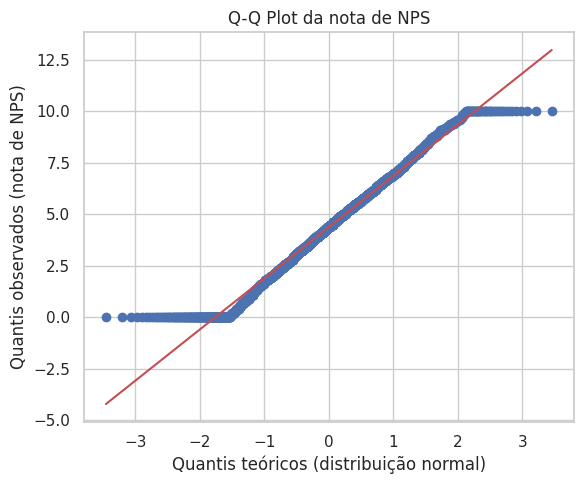

In [22]:
# ============================================================
# Célula 22 — A nota segue uma distribuição normal? (Shapiro-Wilk + QQ-plot)
# ============================================================
# H₀: os dados seguem uma distribuição normal | H₁: os dados não seguem uma distribuição normal
estatistica, p_valor = stats.shapiro(df["nps_score"])
print(f"Shapiro-Wilk: W = {estatistica:.4f} | p-valor = {p_valor:.2e}")
if p_valor > 0.05:
    print("✓ Não rejeitamos H₀: não há evidência contra a normalidade (p-valor > 0,05)")
else:
    print("✗ Rejeitamos H₀: a nota NÃO segue uma distribuição normal (p-valor <= 0,05)")

# QQ-plot: se os pontos acompanharem a reta vermelha, a distribuição se parece com a normal
plt.figure(figsize=(6, 5))
stats.probplot(df["nps_score"], dist="norm", plot=plt)
plt.title("Q-Q Plot da nota de NPS")
plt.xlabel("Quantis teóricos (distribuição normal)")
plt.ylabel("Quantis observados (nota de NPS)")
plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- **Shapiro-Wilk:** W = 0,9817 e p-valor = 2,14 × 10⁻¹⁷, muito abaixo de 0,05. **Rejeitamos H₀: a nota não segue uma distribuição normal.**
- **QQ-plot:** no centro, os pontos acompanham a reta. Nas pontas, formam **linhas horizontais em 0 e em 10**: é o efeito do corte da escala visto na célula anterior.
- **Consequências:**
  - Nos testes de hipótese, damos preferência aos **testes não paramétricos** (Mann-Whitney, Kruskal-Wallis, Spearman).
  - Para o intervalo de confiança, o **bootstrap** é a opção mais segura. Como n = 2.500, o **Teorema Central do Limite** também garante que a **média** se comporta de forma aproximadamente normal (Célula 25).

In [23]:
# ============================================================
# Célula 23 — Classificando os clientes em detratores, neutros e promotores
# ============================================================
# Regra do NPS (notas inteiras): 0 a 6 = detrator | 7 e 8 = neutro | 9 e 10 = promotor.
# Como a base tem decimais, usamos a leitura "nota truncada": abaixo de 7 é detrator (6,9 ainda é 6).
# right=False cria os intervalos [0, 7), [7, 9) e [9, 10]
df["categoria_nps"] = pd.cut(df["nps_score"], bins=[0, 7, 9, 10.01], right=False,
                             labels=["Detrator", "Neutro", "Promotor"])
df["detrator"] = (df["categoria_nps"] == "Detrator").astype(int)   # 1 = detrator, 0 = não detrator

# Função que calcula o NPS: % de promotores − % de detratores (vai de −100 a +100)
def calcular_nps(categorias):
    perc_promotores = (categorias == "Promotor").mean() * 100
    perc_detratores = (categorias == "Detrator").mean() * 100
    return perc_promotores - perc_detratores

composicao = pd.DataFrame({
    "clientes": df["categoria_nps"].value_counts().sort_index(),
    "%": df["categoria_nps"].value_counts(normalize=True).sort_index() * 100,
})
print(composicao)
print(f"\nNPS da empresa = {calcular_nps(df['categoria_nps']):.1f}")

# Sensibilidade: a conclusão muda se arredondarmos as notas em vez de truncar?
categoria_arredondada = pd.cut(df["nps_score"].round(), bins=[0, 7, 9, 10.01], right=False,
                               labels=["Detrator", "Neutro", "Promotor"])
print(f"NPS com notas arredondadas = {calcular_nps(categoria_arredondada):.1f} "
      f"({(categoria_arredondada == 'Detrator').mean():.1%} de detratores)")

               clientes      %
categoria_nps                 
Detrator           2109 84.360
Neutro              281 11.240
Promotor            110  4.400

NPS da empresa = -80.0
NPS com notas arredondadas = -74.1 (80.0% de detratores)


### 📝 Análise dos resultados


- **2.109 detratores (84,4%)**, **281 neutros (11,2%)** e apenas **110 promotores (4,4%)**.
- **NPS da empresa = −80,0.** Para cada promotor existem cerca de **19 detratores**. Um NPS positivo exige mais promotores que detratores; aqui estamos muito longe disso.
- **Sensibilidade:** arredondando as notas em vez de truncar, os detratores caem para 80,0% e o NPS vai para **−74,1**. A regra muda o número em cerca de 6 pontos, mas **não muda a conclusão**: o NPS é extremamente negativo.

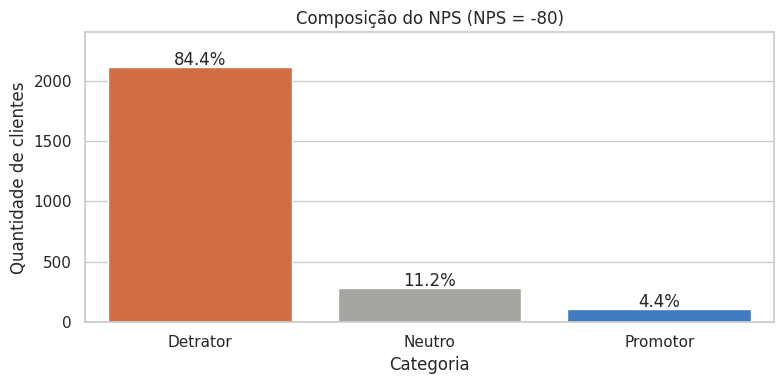

In [24]:
# ============================================================
# Célula 24 — Gráfico de composição: detratores, neutros e promotores
# ============================================================
plt.figure(figsize=(8, 4))
ax = sns.countplot(data=df, x="categoria_nps", hue="categoria_nps", palette=cores_nps, legend=False,
                   order=["Detrator", "Neutro", "Promotor"])

# Escreve o percentual em cima de cada barra
for barra in ax.patches:
    altura = barra.get_height()
    ax.text(barra.get_x() + barra.get_width() / 2, altura + 20, f"{altura / len(df):.1%}", ha="center")

plt.title(f"Composição do NPS (NPS = {calcular_nps(df['categoria_nps']):.0f})")
plt.xlabel("Categoria")
plt.ylabel("Quantidade de clientes")
plt.ylim(0, 2400)
plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- O gráfico de comparação deixa a desproporção evidente: a barra de detratores é quase **8 vezes** maior que a de neutros e **19 vezes** maior que a de promotores.
- Cada barra traz o percentual escrito, para que a leitura não dependa apenas da cor.

Média da nota: 4.379
IC 95% Z-score:     [4.280 ; 4.477]
IC 95% t-Student:   [4.280 ; 4.477]
IC 95% Bootstrap:   [4.283 ; 4.478]


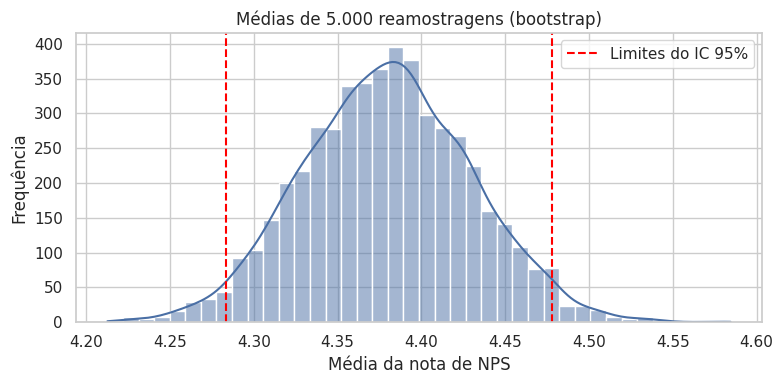

In [25]:
# ============================================================
# Célula 25 — Intervalo de confiança (95%) para a média da nota
# ============================================================
n = len(df)
media = df["nps_score"].mean()
erro_padrao = df["nps_score"].std() / np.sqrt(n)

# (1) Z-score: amostra grande (n >= 30), apoiada no Teorema Central do Limite
ic_z = stats.norm.interval(0.95, loc=media, scale=erro_padrao)

# (2) t-Student: indicado para amostras pequenas (n < 30); aqui serve de comparação
ic_t = stats.t.interval(0.95, df=n - 1, loc=media, scale=erro_padrao)

# (3) Bootstrap: reamostragem com reposição, sem supor normalidade (a nota NÃO é normal)
medias_bootstrap = [np.random.choice(df["nps_score"], size=n, replace=True).mean() for _ in range(5000)]
ic_bootstrap = np.percentile(medias_bootstrap, [2.5, 97.5])

print(f"Média da nota: {media:.3f}")
print(f"IC 95% Z-score:     [{ic_z[0]:.3f} ; {ic_z[1]:.3f}]")
print(f"IC 95% t-Student:   [{ic_t[0]:.3f} ; {ic_t[1]:.3f}]")
print(f"IC 95% Bootstrap:   [{ic_bootstrap[0]:.3f} ; {ic_bootstrap[1]:.3f}]")

# Distribuição das médias do bootstrap: mesmo com a nota não normal, a MÉDIA tende à normal
plt.figure(figsize=(8, 4))
sns.histplot(medias_bootstrap, bins=40, kde=True, color="#4A6FA5")
plt.axvline(ic_bootstrap[0], color="red", linestyle="--", label="Limites do IC 95%")
plt.axvline(ic_bootstrap[1], color="red", linestyle="--")
plt.title("Médias de 5.000 reamostragens (bootstrap)")
plt.xlabel("Média da nota de NPS")
plt.ylabel("Frequência")
plt.legend()
plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- **Média da nota: 4,379.**
- **IC 95% pelo Z-score:** de 4,280 a 4,477. **Pelo t-Student:** o mesmo intervalo, porque com n = 2.500 a distribuição t fica praticamente igual à normal (muitos graus de liberdade). **Pelo bootstrap:** de 4,283 a 4,478, quase idêntico.
- O histograma das médias do bootstrap tem forma de **sino**, mesmo a nota não sendo normal: é o **Teorema Central do Limite** na prática.
- **Interpretação correta do IC de 95%:** se repetíssemos a coleta muitas vezes, cerca de 95% dos intervalos construídos assim conteriam a média verdadeira. O intervalo é estreito (± 0,1 ponto), então a estimativa é precisa.

In [26]:
# ============================================================
# Célula 26 — Intervalo de confiança para proporções (Wilson) e para o NPS (bootstrap)
# ============================================================
# Para proporções (como % de detratores), o intervalo de Wilson é o mais recomendado
for categoria in ["Detrator", "Neutro", "Promotor"]:
    quantidade = (df["categoria_nps"] == categoria).sum()
    ic_inf, ic_sup = proportion_confint(quantidade, n, alpha=0.05, method="wilson")
    print(f"{categoria:9s}: {quantidade / n:.1%}  | IC 95% Wilson: [{ic_inf:.1%} ; {ic_sup:.1%}]")

# O NPS é uma diferença de proporções: usamos o bootstrap para o intervalo
nps_bootstrap = []
for _ in range(5000):
    amostra = np.random.choice(df["categoria_nps"].astype(str), size=n, replace=True)
    nps_bootstrap.append(calcular_nps(amostra))
ic_nps = np.percentile(nps_bootstrap, [2.5, 97.5])
print(f"\nNPS = {calcular_nps(df['categoria_nps']):.1f} | IC 95% bootstrap: [{ic_nps[0]:.1f} ; {ic_nps[1]:.1f}]")

Detrator : 84.4%  | IC 95% Wilson: [82.9% ; 85.7%]
Neutro   : 11.2%  | IC 95% Wilson: [10.1% ; 12.5%]
Promotor : 4.4%  | IC 95% Wilson: [3.7% ; 5.3%]



NPS = -80.0 | IC 95% bootstrap: [-81.8 ; -78.0]


### 📝 Análise dos resultados


- **Detratores:** 84,4% (IC 95% de Wilson: 82,9% a 85,7%). **Neutros:** 11,2% (10,1% a 12,5%). **Promotores:** 4,4% (3,7% a 5,3%).
- **NPS:** −80,0, com IC 95% bootstrap de **−81,8 a −78,0**.
- Os intervalos são estreitos: o diagnóstico de NPS muito negativo **não é fruto do acaso amostral**.
- **Cuidado:** o intervalo de confiança mede apenas a incerteza da amostragem. Ele **não corrige o viés de autosseleção** da pesquisa (só responde quem quer). Se quem não respondeu estiver mais satisfeito, o NPS real pode ser menos negativo.

# 7. 🔗 Relação entre variáveis e descoberta de padrões

Até aqui olhamos cada variável sozinha. Agora cruzamos as variáveis com a nota para descobrir padrões. Seguimos a lógica do tipo de variável:

- **Numérica × numérica:** gráfico de dispersão (scatter) + correlação.
- **Numérica × categórica:** boxplot por grupo + estatísticas por grupo (`groupby`).
- **Categórica × categórica:** tabela cruzada (`pd.crosstab`) + barras empilhadas.

⚠️ Lembrete constante: **correlação não significa causalidade**. Duas variáveis podem andar juntas porque ambas dependem de uma terceira (uma *variável de confusão*).

## 7.1 Variáveis numéricas × nota de NPS

In [27]:
# ============================================================
# Célula 27 — Correlação de cada variável com a nota (Pearson e Spearman)
# ============================================================
# Pearson mede relação LINEAR; Spearman mede relação MONOTÔNICA (sobe junto/desce junto) e é mais robusta
explicativas = [c for c in numericas if c != alvo]
correlacoes = pd.DataFrame({
    "pearson": df[explicativas].corrwith(df[alvo]),
    "spearman": df[explicativas].corrwith(df[alvo], method="spearman"),
})

# Indica o momento em que cada variável é registrada (importante para o risco de vazamento)
correlacoes["momento"] = ["Antes" if c in antes_da_pesquisa else
                          "Incerto" if c in momento_incerto else "Depois" for c in correlacoes.index]
correlacoes.sort_values("spearman")

,pearson,spearman,momento
delivery_delay_days,-0.597,-0.586,Antes
complaints_count,-0.497,-0.490,Incerto
customer_service_contacts,-0.351,-0.336,Incerto
resolution_time_days,-0.191,-0.190,Incerto
freight_value,-0.041,-0.040,Antes
customer_tenure_months,-0.010,-0.012,Antes
customer_age,-0.010,-0.007,Antes
delivery_time_days,0.001,0.000,Antes
items_quantity,0.011,0.006,Antes
discount_value,0.025,0.012,Antes


### 📝 Análise dos resultados


Três grupos aparecem com clareza:

1. **Fatores de experiência ruim, os únicos com relação relevante com a nota:**
   - **atraso na entrega** (Spearman −0,59), a correlação mais forte da base;
   - **reclamações** (−0,49);
   - **contatos com o SAC** (−0,34);
   - **tempo de resolução** (−0,19).
2. **Variáveis sem relação com a nota (|ρ| ≤ 0,04):** idade, tempo de relacionamento, valor do pedido, itens, parcelas, desconto, frete, tentativas de entrega e, surpreendentemente, **tempo total de entrega** (0,00).
3. **Variáveis que acompanham a nota, mas não podem explicá-la:** CSAT (+0,56), que é outra medida de satisfação, e **recompra** (+0,49), registrada **depois** da pesquisa. Usá-las como explicativas seria **vazamento de dados**.

Pearson e Spearman são quase iguais em todas as variáveis: as relações são aproximadamente lineares e não são puxadas por outliers. **Correlação não significa causalidade:** estes números mostram o que anda junto com a nota, e não o que causa a nota.

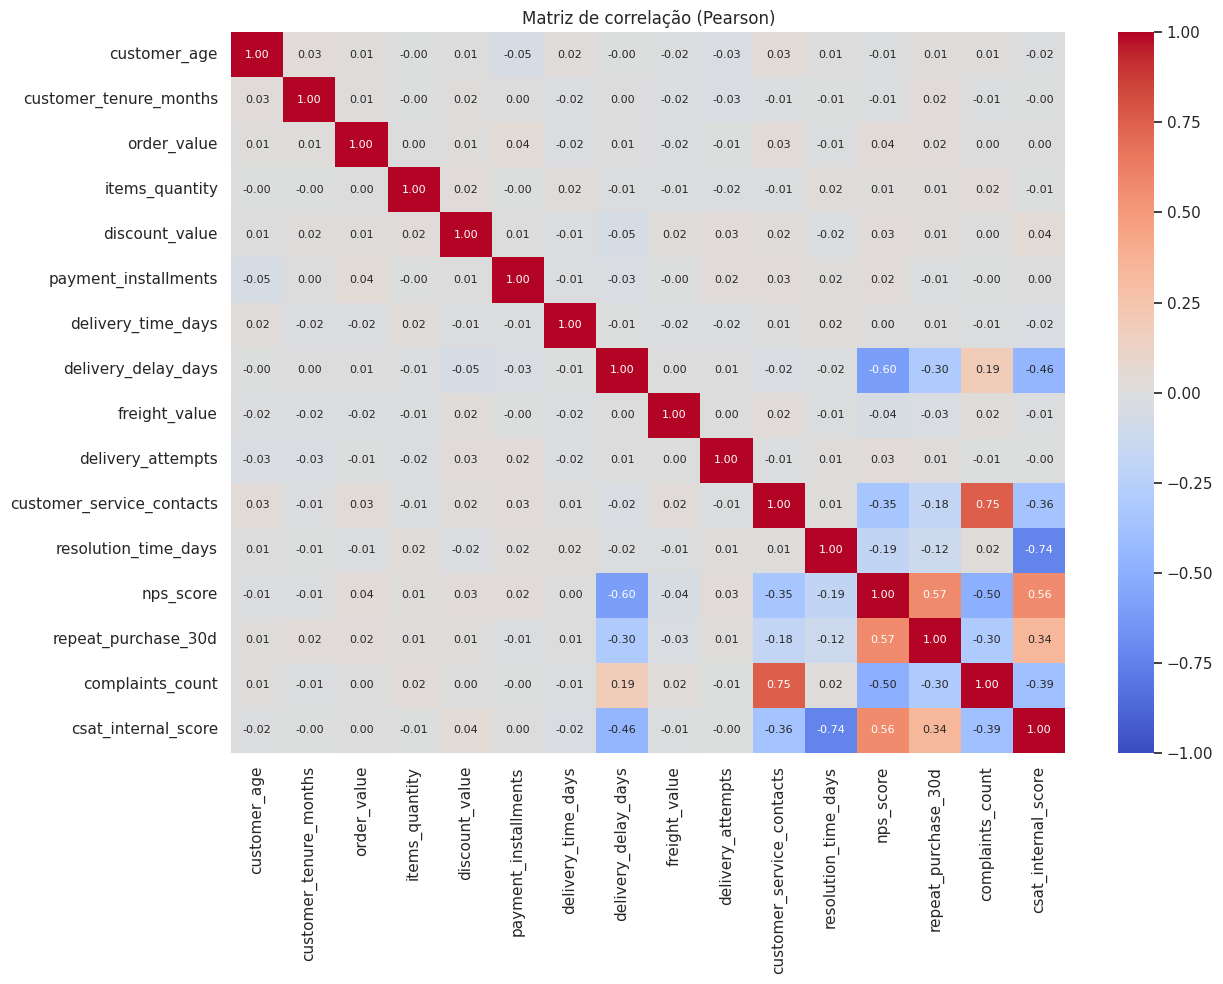

In [28]:
# ============================================================
# Célula 28 — Heatmap de correlação: blocos de variáveis que se movem juntas
# ============================================================
corr = df[numericas].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Matriz de correlação (Pearson)")
plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


O heatmap mostra três blocos de variáveis que se movem juntas:

- **Contatos com o SAC × reclamações: 0,75.** As duas medem quase o mesmo fenômeno (um cliente com problema). Em um modelo, essa redundância (**multicolinearidade**) divide o efeito entre as duas e deixa os coeficientes individuais instáveis.
- **CSAT × tempo de resolução: −0,74.** O CSAT interno é, basicamente, uma medida da resolução do atendimento.
- **Atraso × reclamações: 0,19.** Parte das reclamações pode ser **consequência do atraso**. É um exemplo de possível variável de confusão: o atraso pode estar por trás tanto da reclamação quanto da nota baixa.

Fora desses blocos, quase tudo é próximo de zero (cores claras). Em dados reais seria natural, por exemplo, o frete acompanhar o valor do pedido. A ausência total dessas relações é mais um sinal de base simulada.

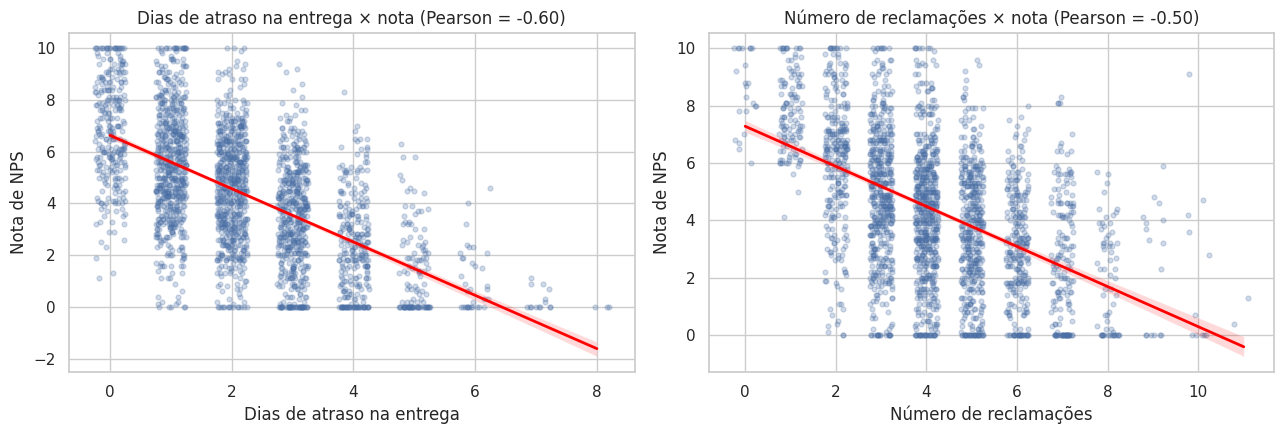

In [29]:
# ============================================================
# Célula 29 — Dispersão com linha de tendência: atraso e reclamações × nota
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, coluna, titulo in zip(axes, ["delivery_delay_days", "complaints_count"],
                              ["Dias de atraso na entrega", "Número de reclamações"]):
    # x_jitter espalha um pouco os pontos para não ficarem empilhados (as variáveis são discretas)
    sns.regplot(data=df, x=coluna, y="nps_score", x_jitter=0.25, ax=ax,
                scatter_kws={"alpha": 0.25, "s": 12, "color": "#4A6FA5"},
                line_kws={"color": "red", "lw": 2})
    ax.set_title(f"{titulo} × nota (Pearson = {df[coluna].corr(df['nps_score']):.2f})")
    ax.set_xlabel(titulo)
    ax.set_ylabel("Nota de NPS")

plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- **Atraso × nota:** a linha de tendência desce de forma clara (Pearson −0,60). Cada dia de atraso derruba a nota em cerca de 1 ponto.
- **Reclamações × nota:** a tendência também é de queda (Pearson −0,50), um pouco mais suave.
- Dentro de cada nível há **muita dispersão** (pedidos com o mesmo atraso recebem notas de 0 a 10): outros fatores também pesam.
- A linha de tendência do atraso **cruza abaixo de zero** a partir de cerca de 7 dias, um valor impossível na escala. É um lembrete de que a nota é limitada entre 0 e 10, e uma reta não respeita esse limite.

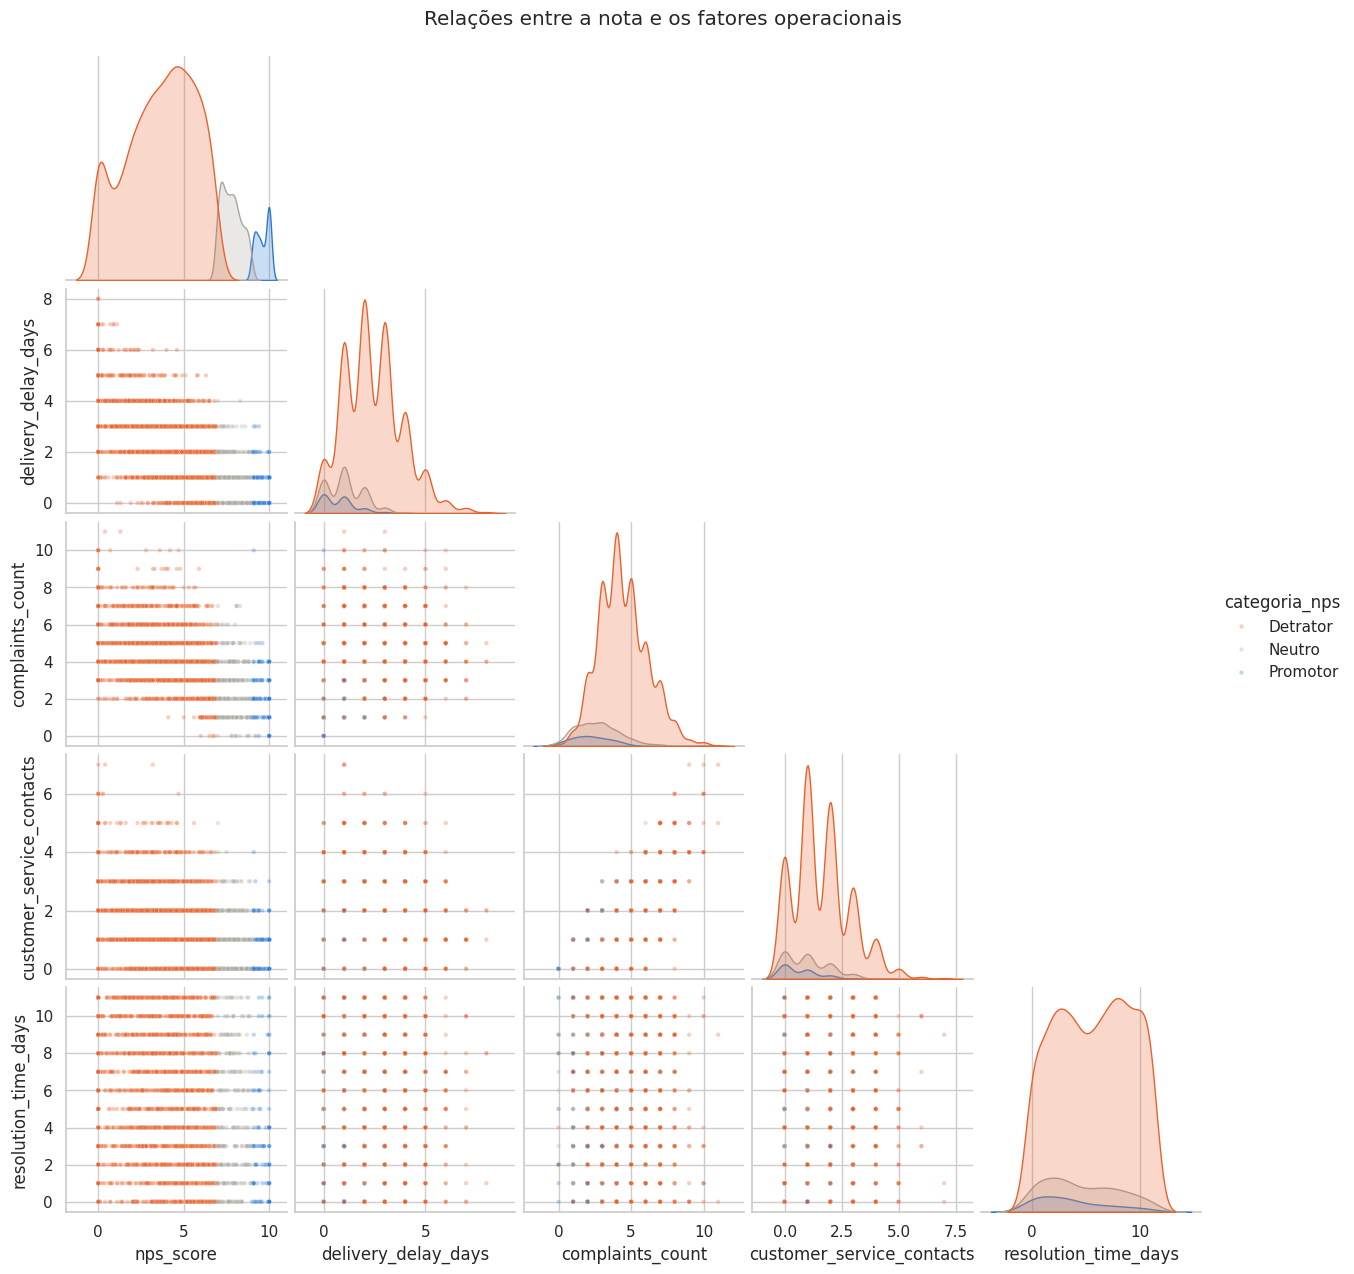

In [30]:
# ============================================================
# Célula 30 — Pairplot: várias relações de uma só vez
# ============================================================
principais = ["nps_score", "delivery_delay_days", "complaints_count",
              "customer_service_contacts", "resolution_time_days"]

sns.pairplot(df[principais + ["categoria_nps"]], hue="categoria_nps", palette=cores_nps,
             corner=True, plot_kws={"alpha": 0.3, "s": 10})
plt.suptitle("Relações entre a nota e os fatores operacionais", y=1.02)
plt.show()

### 📝 Análise dos resultados


- Os **promotores (azul)** se concentram nos valores **baixos de atraso e de reclamações**. Os detratores (laranja) se espalham por todo o resto.
- Nos gráficos da diagonal, a distribuição dos promotores fica quase toda entre 0 e 2 dias de atraso.
- O tempo de resolução não separa bem as categorias: as três se misturam ao longo de toda a faixa de 0 a 11 dias, o que confirma o seu efeito menor.

## 7.2 Entrega: atraso e prazo (H1)

In [31]:
# ============================================================
# Célula 31 — Nota, % de detratores e NPS por dias de atraso
# ============================================================
tabela_atraso = df.groupby("delivery_delay_days").agg(
    pedidos=("nps_score", "count"),
    nota_media=("nps_score", "mean"),
    nota_mediana=("nps_score", "median"),
    perc_detratores=("detrator", "mean"),
)
tabela_atraso["perc_detratores"] = tabela_atraso["perc_detratores"] * 100
tabela_atraso["NPS"] = df.groupby("delivery_delay_days")["categoria_nps"].apply(calcular_nps)
tabela_atraso

,pedidos,nota_media,nota_mediana,perc_detratores,NPS
delivery_delay_days,,,,,
0,277,6.857,6.800,51.625,-33.574
1,615,5.546,5.500,73.984,-66.829
2,646,4.580,4.600,87.926,-85.913
3,525,3.437,3.400,96.762,-96.190
4,270,2.444,2.300,99.259,-99.259
5,116,1.481,1.250,100.000,-100.000
6,34,1.097,0.700,100.000,-100.000
7,14,0.293,0.000,100.000,-100.000
8,3,0.000,0.000,100.000,-100.000


### 📝 Análise dos resultados


| Dias de atraso | Nota média | % detratores | NPS |
|---|---|---|---|
| 0 | 6,86 | 51,6% | −33,6 |
| 1 | 5,55 | 74,0% | −66,8 |
| 2 | 4,58 | 87,9% | −85,9 |
| 3 | 3,44 | 96,8% | −96,2 |
| 4 | 2,44 | 99,3% | −99,3 |
| 5 ou mais | 1,48 ou menos | 100% | −100 |

- A nota cai **cerca de 1 ponto a cada dia de atraso**, de forma quase linear.
- Os grupos de 6, 7 e 8 dias são muito pequenos (34, 14 e 3 pedidos), por isso foram agrupados em "5+" nos gráficos.
- **Mesmo sem atraso, o NPS é −33,6** e metade dos clientes é detratora: o atraso explica muito, mas não tudo.

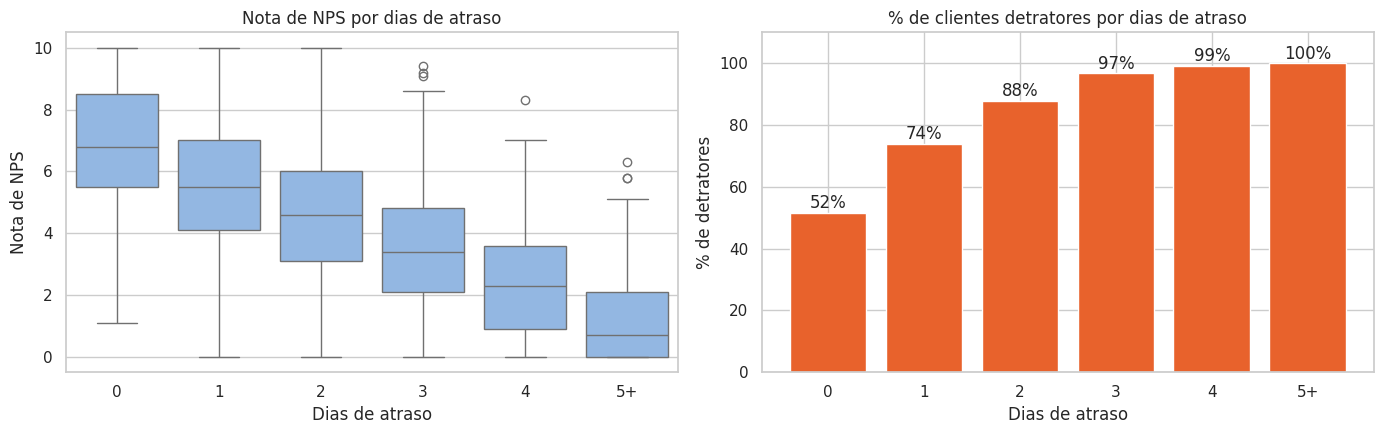

In [32]:
# ============================================================
# Célula 32 — Visualizando o efeito do atraso (comparação entre grupos)
# ============================================================
# Agrupa 5 dias ou mais em "5+" porque os grupos de 6, 7 e 8 dias são muito pequenos
df["atraso_grupo"] = df["delivery_delay_days"].clip(upper=5).astype(str).replace("5", "5+")
ordem = ["0", "1", "2", "3", "4", "5+"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Boxplot: mediana, dispersão e outliers da nota em cada grupo
sns.boxplot(data=df, x="atraso_grupo", y="nps_score", order=ordem, color="#86B6EF", ax=axes[0])
axes[0].set_title("Nota de NPS por dias de atraso")
axes[0].set_xlabel("Dias de atraso")
axes[0].set_ylabel("Nota de NPS")

# Barras: % de detratores em cada grupo
perc_det = df.groupby("atraso_grupo")["detrator"].mean().reindex(ordem) * 100
axes[1].bar(perc_det.index, perc_det.values, color="#E8622C")
for i, v in enumerate(perc_det.values):
    axes[1].text(i, v + 1.5, f"{v:.0f}%", ha="center")
axes[1].set_ylim(0, 110)
axes[1].set_title("% de clientes detratores por dias de atraso")
axes[1].set_xlabel("Dias de atraso")
axes[1].set_ylabel("% de detratores")

plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- O boxplot mostra a **mediana descendo degrau a degrau**, de 6,8 (sem atraso) até menos de 1 (5 dias ou mais).
- A proporção de detratores sobe de **52% → 74% → 88% → 97% → 99% → 100%**.
- **Pontos de ruptura:**
  - **1º dia de atraso:** é o maior salto da jornada (+22 pontos percentuais de detratores; o NPS cai de −34 para −67).
  - **3º dia de atraso:** a partir daqui, 97% ou mais dos clientes já são detratores. É o "ponto sem volta": depois dele, só resta recuperar o cliente.
- **H1 se sustenta visualmente**, e os testes da Seção 8 confirmam.

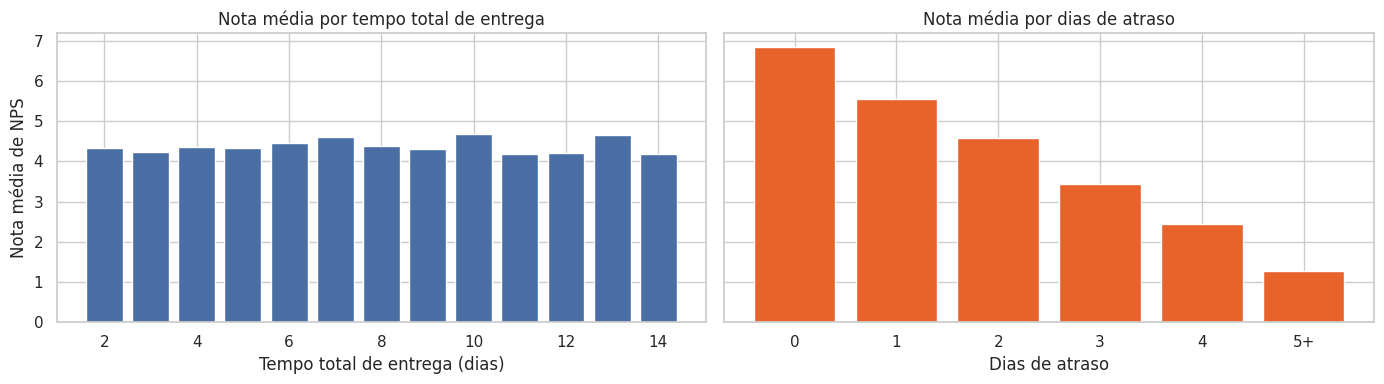

Correlação de Spearman com a nota:
  tempo total de entrega: 0.000
  dias de atraso:         -0.586

Entrega longa (12-14 dias) no prazo   :   70 pedidos | nota média 7.0 | 44% detratores
Entrega rápida (2-4 dias) com 2+ dias de atraso:  381 pedidos | nota média 3.4 | 94% detratores


In [33]:
# ============================================================
# Célula 33 — O que pesa: o prazo total ou o prazo descumprido?
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

# Nota média por tempo total de entrega (2 a 14 dias)
media_por_prazo = df.groupby("delivery_time_days")["nps_score"].mean()
axes[0].bar(media_por_prazo.index, media_por_prazo.values, color="#4A6FA5")
axes[0].set_title("Nota média por tempo total de entrega")
axes[0].set_xlabel("Tempo total de entrega (dias)")
axes[0].set_ylabel("Nota média de NPS")

# Nota média por dias de atraso
media_por_atraso = df.groupby("atraso_grupo")["nps_score"].mean().reindex(ordem)
axes[1].bar(media_por_atraso.index, media_por_atraso.values, color="#E8622C")
axes[1].set_title("Nota média por dias de atraso")
axes[1].set_xlabel("Dias de atraso")

plt.tight_layout()
plt.show()

print("Correlação de Spearman com a nota:")
print(f"  tempo total de entrega: {stats.spearmanr(df['delivery_time_days'], df['nps_score'])[0]:.3f}")
print(f"  dias de atraso:         {stats.spearmanr(df['delivery_delay_days'], df['nps_score'])[0]:.3f}")

# Exemplo concreto: entrega longa no prazo × entrega rápida atrasada
longa_no_prazo = (df["delivery_time_days"] >= 12) & (df["delivery_delay_days"] == 0)
rapida_atrasada = (df["delivery_time_days"] <= 4) & (df["delivery_delay_days"] >= 2)
print(f"\nEntrega longa (12-14 dias) no prazo   : {longa_no_prazo.sum():4d} pedidos | "
      f"nota média {df.loc[longa_no_prazo, 'nps_score'].mean():.1f} | "
      f"{df.loc[longa_no_prazo, 'detrator'].mean():.0%} detratores")
print(f"Entrega rápida (2-4 dias) com 2+ dias de atraso: {rapida_atrasada.sum():4d} pedidos | "
      f"nota média {df.loc[rapida_atrasada, 'nps_score'].mean():.1f} | "
      f"{df.loc[rapida_atrasada, 'detrator'].mean():.0%} detratores")

### 📝 Análise dos resultados


- **Tempo total de entrega:** a nota média fica praticamente estável, entre 4,19 e 4,69, de 2 a 14 dias. A correlação de Spearman é **0,000**.
- **Dias de atraso:** a nota média despenca a cada dia (Spearman **−0,586**).
- **Exemplo concreto:**
  - **Entrega longa (12 a 14 dias) dentro do prazo:** 70 pedidos, nota média de **7,0** e 44% de detratores.
  - **Entrega rápida (2 a 4 dias) com 2 ou mais dias de atraso:** 381 pedidos, nota média de **3,4** e 94% de detratores.
- **Conclusão:** o cliente **aceita esperar, mas não aceita a promessa quebrada**. Prometer prazos realistas pode valer mais do que entregar mais rápido.
- **Cuidado:** o grupo de entregas longas no prazo é pequeno (70 pedidos), porque quase todos os pedidos atrasam.

## 7.3 Atendimento: contatos, reclamações e tempo de resolução (H2, H3)

In [34]:
# ============================================================
# Célula 34 — Nota e NPS por contatos, reclamações e tempo de resolução
# ============================================================
# Agrupa os valores raros no topo (5+ contatos, 8+ reclamações) para não tirar conclusões de grupos minúsculos
df["contatos_grupo"] = df["customer_service_contacts"].clip(upper=5)
df["reclamacoes_grupo"] = df["complaints_count"].clip(upper=8)

for coluna, nome in [("contatos_grupo", "CONTATOS COM O SAC (5 = 5 ou mais)"),
                     ("reclamacoes_grupo", "RECLAMAÇÕES (8 = 8 ou mais)"),
                     ("resolution_time_days", "TEMPO DE RESOLUÇÃO (dias)")]:
    tabela = df.groupby(coluna).agg(pedidos=("nps_score", "count"),
                                    nota_media=("nps_score", "mean"),
                                    perc_detratores=("detrator", "mean"))
    tabela["perc_detratores"] = tabela["perc_detratores"] * 100
    tabela["NPS"] = df.groupby(coluna)["categoria_nps"].apply(calcular_nps)
    print(f"\n{nome}")
    print(tabela.round(1))


CONTATOS COM O SAC (5 = 5 ou mais)
                pedidos  nota_media  perc_detratores     NPS
contatos_grupo                                              
0                   554       5.500           70.800 -60.500
1                   816       4.700           83.900 -79.500
2                   640       4.100           88.600 -86.400
3                   314       3.200           93.300 -92.700
4                   132       2.700           97.700 -97.000
5                    44       1.900           97.700 -97.700

RECLAMAÇÕES (8 = 8 ou mais)
                   pedidos  nota_media  perc_detratores     NPS
reclamacoes_grupo                                              
0                       23       8.500           17.400  21.700
1                      122       7.800           30.300  -9.000
2                      277       6.100           65.300 -54.200
3                      507       4.900           81.700 -77.100
4                      600       4.200           89.800 -87.000

### 📝 Análise dos resultados


- **Contatos com o SAC:** o NPS cai de **−60,5 (nenhum contato)** para −79,5 (1 contato), −86,4 (2) e −97,0 (4). Cada contato a mais sinaliza um problema não resolvido.
- **Reclamações:** é a variável com maior amplitude.
  - Clientes **sem reclamação têm NPS positivo (+21,7)**, mas são apenas 23 pedidos, um grupo pequeno que deve ser lido com cautela.
  - Com 1 reclamação o NPS já é −9,0; com 2, −54,2; a partir de 6, fica perto de −97.
- **Tempo de resolução:** a queda é mais suave e um pouco irregular. Vai de −65,4 (resolução no mesmo dia) a cerca de −89 (10 e 11 dias), e há oscilações no meio (com 3 dias, −71,3, melhor que com 2 dias, −76,4).

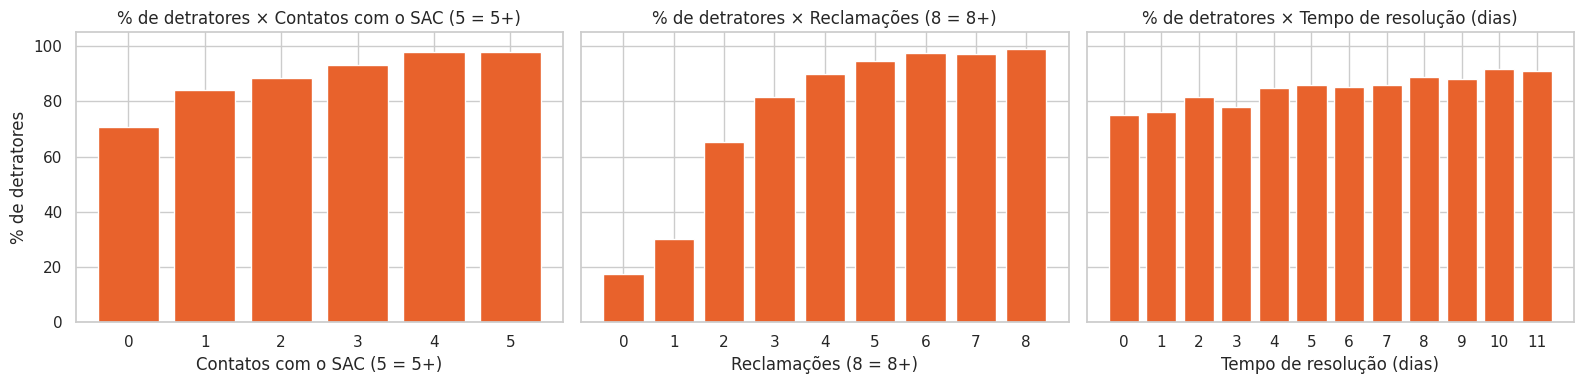

In [35]:
# ============================================================
# Célula 35 — Visualizando o atendimento: % de detratores por nível
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

for ax, coluna, titulo in zip(axes,
                              ["contatos_grupo", "reclamacoes_grupo", "resolution_time_days"],
                              ["Contatos com o SAC (5 = 5+)", "Reclamações (8 = 8+)", "Tempo de resolução (dias)"]):
    perc = df.groupby(coluna)["detrator"].mean() * 100
    ax.bar(perc.index.astype(str), perc.values, color="#E8622C")
    ax.set_title(f"% de detratores × {titulo}")
    ax.set_xlabel(titulo)

axes[0].set_ylabel("% de detratores")
axes[0].set_ylim(0, 105)
plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- **Contatos com o SAC:** a proporção de detratores sobe de 71% (nenhum contato) para 98% (5 ou mais).
- **Reclamações:** 17% de detratores sem reclamação, 30% com 1 e **65% com 2**. A **2ª reclamação** é um ponto de ruptura (+35 pontos percentuais): o cliente tolera um problema, mas não dois.
- **Tempo de resolução:** sobe de forma gradual, de 75% para cerca de 91%.
- **Leitura de negócio:** o **volume de problemas** (reclamações e contatos) pesa mais do que a velocidade de resolução. Prevenir o problema vale mais do que resolvê-lo rápido, mas resolver rápido ainda ajuda.
- **Cuidado com a causalidade e o momento:** reclamações e contatos podem ter sido registrados **depois** da pesquisa, ou ser **consequência do atraso**. É preciso confirmar a ordem dos eventos com o negócio.

## 7.4 Pricing e perfil do cliente (H4, H6)

In [36]:
# ============================================================
# Célula 36 — A nota muda com preço, frete, desconto, idade ou tempo de casa?
# ============================================================
# Criamos faixas (categorias) a partir das variáveis contínuas para comparar grupos
df["faixa_idade"] = pd.cut(df["customer_age"], bins=[17, 29, 39, 49, 59, 69],
                           labels=["18-29", "30-39", "40-49", "50-59", "60-69"])
df["faixa_relacionamento"] = pd.cut(df["customer_tenure_months"], bins=[0, 12, 36, 60, 120],
                                    labels=["até 1 ano", "1-3 anos", "3-5 anos", "5-10 anos"])
df["faixa_valor"] = pd.qcut(df["order_value"], q=4, labels=["1º quartil", "2º quartil", "3º quartil", "4º quartil"])
df["faixa_frete"] = pd.qcut(df["freight_value"], q=4, labels=["1º quartil", "2º quartil", "3º quartil", "4º quartil"])
df["faixa_desconto"] = pd.qcut(df["discount_value"], q=4, labels=["1º quartil", "2º quartil", "3º quartil", "4º quartil"])

for faixa in ["faixa_idade", "faixa_relacionamento", "faixa_valor", "faixa_frete", "faixa_desconto"]:
    tabela = df.groupby(faixa, observed=True).agg(pedidos=("nps_score", "count"),
                                                 nota_media=("nps_score", "mean"),
                                                 perc_detratores=("detrator", "mean"))
    tabela["perc_detratores"] = tabela["perc_detratores"] * 100
    tabela["NPS"] = df.groupby(faixa, observed=True)["categoria_nps"].apply(calcular_nps)
    print(f"\n{faixa.upper()}")
    print(tabela.round(1))


FAIXA_IDADE
             pedidos  nota_media  perc_detratores     NPS
faixa_idade                                              
18-29            561       4.500           82.700 -78.400
30-39            498       4.200           85.100 -80.300
40-49            496       4.300           87.300 -84.300
50-59            482       4.400           83.600 -78.600
60-69            463       4.500           83.200 -78.200

FAIXA_RELACIONAMENTO
                      pedidos  nota_media  perc_detratores     NPS
faixa_relacionamento                                              
até 1 ano                 242       4.100           86.400 -83.100
1-3 anos                  490       4.600           82.900 -78.000
3-5 anos                  478       4.300           86.200 -83.300
5-10 anos                1290       4.400           83.900 -78.900

FAIXA_VALOR
             pedidos  nota_media  perc_detratores     NPS
faixa_valor                                              
1º quartil       625       4

### 📝 Análise dos resultados


Em todas as faixas, a nota média fica entre **4,1 e 4,6** e o NPS entre cerca de **−85 e −77**:

| Recorte | Variação do NPS entre as faixas |
|---|---|
| Idade | −84,3 a −78,2 |
| Tempo de relacionamento | −83,3 a −78,0 |
| Valor do pedido | −83,5 a −77,0 |
| Valor do frete | −82,4 a −77,3 |
| Desconto | −84,5 a −77,1 |

- As diferenças não seguem nenhuma direção lógica: o NPS não melhora com o desconto nem piora com o frete. São oscilações compatíveis com o acaso, como a Seção 8 confirma com os testes.
- **Leitura de negócio:** a insatisfação **não é um problema de preço nem de perfil de cliente**. Dar mais desconto ou baratear o frete não deve mover o NPS.
- **Limite:** a base só tem quem comprou. O frete pode pesar na **conversão** (quem desistiu de comprar), que esta base não observa.

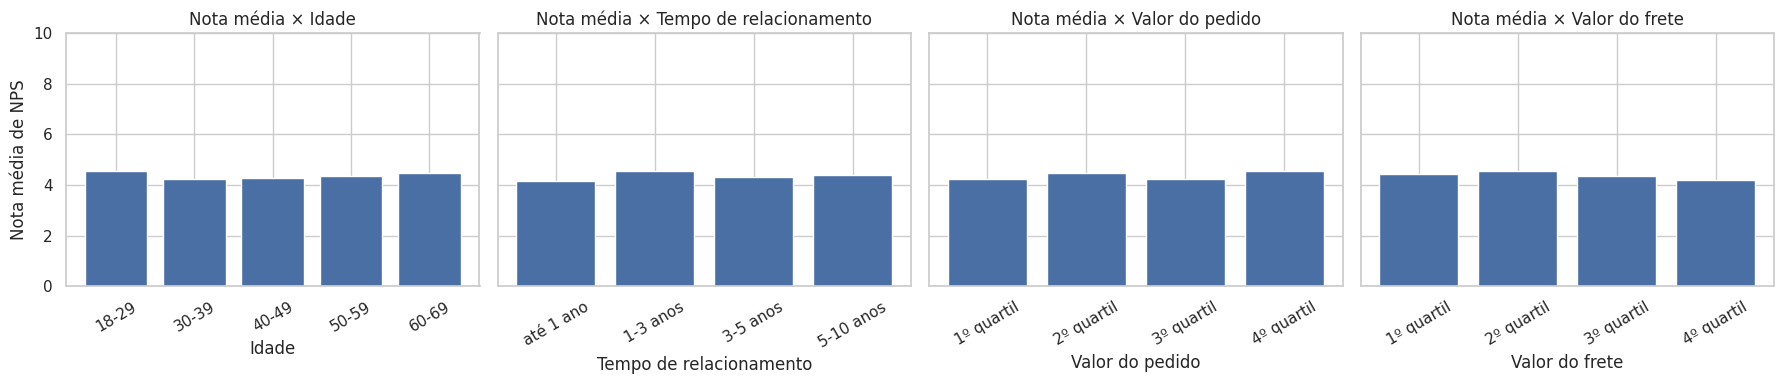

In [37]:
# ============================================================
# Célula 37 — Visualizando preço e perfil: nota média por faixa
# ============================================================
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)

for ax, faixa, titulo in zip(axes, ["faixa_idade", "faixa_relacionamento", "faixa_valor", "faixa_frete"],
                             ["Idade", "Tempo de relacionamento", "Valor do pedido", "Valor do frete"]):
    media = df.groupby(faixa, observed=True)["nps_score"].mean()
    ax.bar(media.index.astype(str), media.values, color="#4A6FA5")
    ax.set_title(f"Nota média × {titulo}")
    ax.set_xlabel(titulo)
    ax.tick_params(axis="x", rotation=30)

axes[0].set_ylabel("Nota média de NPS")
axes[0].set_ylim(0, 10)
plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- Todas as barras têm praticamente a mesma altura: nenhum degrau, nenhuma tendência.
- O eixo vertical começa em 0 e vai até 10, a escala completa da nota, para não exagerar diferenças pequenas (um eixo cortado faria oscilações de 0,3 ponto parecerem grandes).
- O contraste com os gráficos de atraso e de reclamações é a principal mensagem: **o que move a nota é a experiência, não o perfil nem o preço**.

## 7.5 Variáveis categóricas: região (H5)

                  count  mean   std   min   25%   50%   75%    max
customer_region                                                   
Centro-Oeste    468.000 4.210 2.626 0.000 2.100 4.200 6.100 10.000
Nordeste        485.000 4.422 2.435 0.000 2.700 4.500 6.100 10.000
Norte           506.000 4.383 2.486 0.000 2.600 4.500 6.100 10.000
Sudeste         520.000 4.374 2.492 0.000 2.575 4.300 6.100 10.000
Sul             521.000 4.491 2.517 0.000 2.700 4.500 6.300 10.000

NPS por região:
customer_region
Centro-Oeste   -78.800
Nordeste       -81.200
Norte          -81.600
Sudeste        -79.200
Sul            -78.900
Name: categoria_nps, dtype: float64


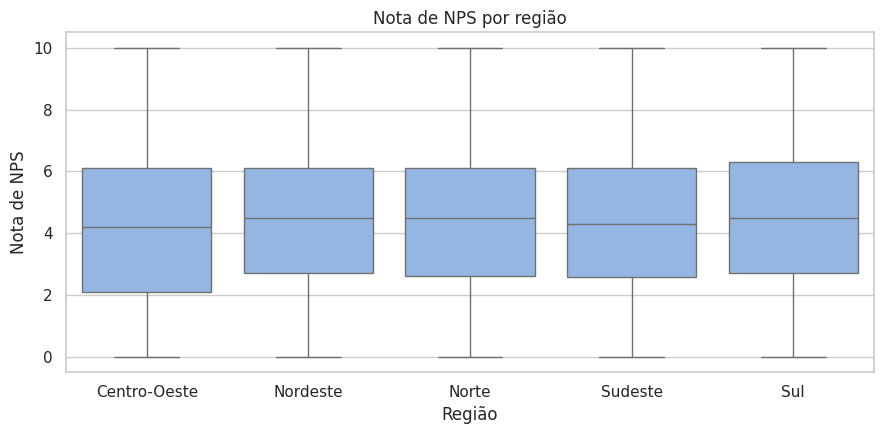

In [38]:
# ============================================================
# Célula 38 — Nota por região: estatísticas por grupo e boxplot
# ============================================================
# groupby + describe: compara o comportamento da nota entre as regiões
print(df.groupby("customer_region")["nps_score"].describe())
print()
print("NPS por região:")
print(df.groupby("customer_region")["categoria_nps"].apply(calcular_nps).round(1))

plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df, x="customer_region", y="nps_score", order=sorted(df["customer_region"].unique()),
            color="#86B6EF")
plt.title("Nota de NPS por região")
plt.xlabel("Região")
plt.ylabel("Nota de NPS")
plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- As notas médias vão de **4,21 (Centro-Oeste) a 4,49 (Sul)**, e as medianas de 4,2 a 4,5. Os desvios padrão também são parecidos (2,4 a 2,6).
- O NPS vai de **−81,6 (Norte) a −78,8 (Centro-Oeste)**. Curiosamente, o Centro-Oeste tem a menor nota média e o melhor NPS: um sinal de que essas diferenças pequenas são **ruído**, e não um padrão real.
- Os boxplots são praticamente idênticos em mediana, quartis e amplitude.
- **Leitura de negócio:** o problema é **nacional**, não de uma região ou transportadora específica. A causa provável está em processos que valem para toda a operação (promessa de prazo, gestão de transportadoras, política de atendimento).

categoria_nps    Detrator  Neutro  Promotor
customer_region                            
Centro-Oeste          394      49        25
Nordeste              415      49        21
Norte                 431      57        18
Sudeste               435      62        23
Sul                   434      64        23


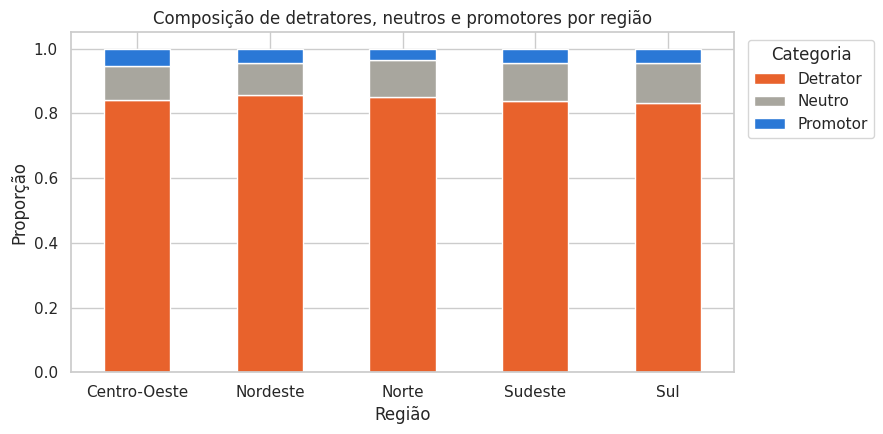

In [39]:
# ============================================================
# Célula 39 — Tabela cruzada: região × categoria de NPS (composição)
# ============================================================
# Contagem de clientes em cada combinação de região e categoria
print(pd.crosstab(df["customer_region"], df["categoria_nps"]))

# normalize="index" transforma em proporção dentro de cada região (cada linha soma 1)
tabela_comp = pd.crosstab(df["customer_region"], df["categoria_nps"], normalize="index")

tabela_comp.plot(kind="bar", stacked=True, figsize=(9, 4.5),
                 color=[cores_nps[c] for c in tabela_comp.columns])
plt.title("Composição de detratores, neutros e promotores por região")
plt.xlabel("Região")
plt.ylabel("Proporção")
plt.xticks(rotation=0)
plt.legend(title="Categoria", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- Em todas as regiões, os detratores representam entre **83% e 86%**, e as barras empilhadas são quase idênticas.
- Esse é o padrão narrativo da **comparação** em que a descoberta é a ausência de diferença: nenhuma região se destaca, para melhor ou para pior.
- O teste qui-quadrado da Seção 8 confirma que a categoria de NPS é independente da região.

## 7.6 Recompra (H7) e CSAT interno (H8)

repeat_purchase_30d     0     1
categoria_nps                  
Detrator            1.000 0.000
Neutro              0.616 0.384
Promotor            0.000 1.000

nota_inteira       0       1       2       3       4       5       6       7       8       9
count        272.000 191.000 286.000 339.000 378.000 351.000 292.000 173.000 108.000 110.000
mean           0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   1.000   1.000

Maior nota entre quem NÃO recomprou: 7.9
Menor nota entre quem recomprou:     8.0


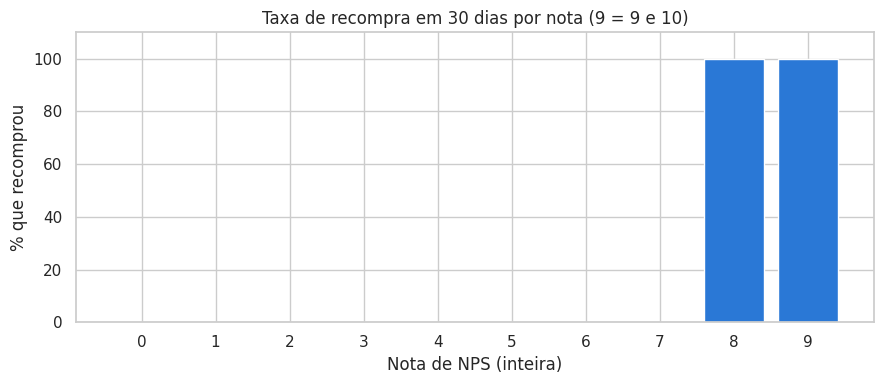

In [40]:
# ============================================================
# Célula 40 — Taxa de recompra por categoria de NPS
# ============================================================
# A recompra é registrada DEPOIS da pesquisa: aqui ela é um resultado de negócio, não uma explicação da nota
print(pd.crosstab(df["categoria_nps"], df["repeat_purchase_30d"], normalize="index").round(3))
print()

# Taxa de recompra por nota inteira (truncada)
df["nota_inteira"] = np.floor(df["nps_score"]).clip(upper=9).astype(int)   # 9 representa 9 e 10
print(df.groupby("nota_inteira")["repeat_purchase_30d"].agg(["count", "mean"]).T.round(3))
print()

# Existe sobreposição entre quem recomprou e quem não recomprou?
print("Maior nota entre quem NÃO recomprou:", df.loc[df["repeat_purchase_30d"] == 0, "nps_score"].max())
print("Menor nota entre quem recomprou:    ", df.loc[df["repeat_purchase_30d"] == 1, "nps_score"].min())

plt.figure(figsize=(9, 4))
taxa = df.groupby("nota_inteira")["repeat_purchase_30d"].mean() * 100
plt.bar(taxa.index.astype(str), taxa.values, color="#2A78D6")
plt.title("Taxa de recompra em 30 dias por nota (9 = 9 e 10)")
plt.xlabel("Nota de NPS (inteira)")
plt.ylabel("% que recomprou")
plt.ylim(0, 110)
plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- **Detratores: 0% de recompra. Neutros: 38,4%. Promotores: 100%.** À primeira vista, a hipótese H7 estaria confirmada de forma espetacular.
- **Mas o padrão é perfeito demais.** Por nota inteira, a recompra é **0% em todas as notas de 0 a 7** e **100% nas notas 8, 9 e 10**. A maior nota entre quem **não** recomprou é **7,9**; a menor entre quem recomprou é **8,0**. A separação é exata, sem nenhuma sobreposição.
- **Interpretação:** em dados reais, a recompra depende de muitos fatores (necessidade, preço, sazonalidade), e haveria detratores que recompram e promotores que não. Um corte exato indica que a coluna foi **derivada da própria nota** (uma regra do tipo "recompra = 1 se nota ≥ 8").
- **Consequências:**
  1. Não dá para medir o **efeito real** do NPS na recompra com estes dados: H7 fica **inconclusiva**.
  2. Usar a recompra para explicar ou prever a nota seria **vazamento total de dados**.
  3. A fronteira está em 8, e não em 9 (limite de promotor): neutros com nota 8 recompram, com nota 7 não.
- **Ação:** questionar a origem desta coluna com a área de negócio antes de qualquer uso.

Correlação de Spearman CSAT × NPS: 0.56
                           com NPS  com CSAT
delivery_delay_days         -0.590    -0.460
complaints_count            -0.490    -0.380
customer_service_contacts   -0.340    -0.360
resolution_time_days        -0.190    -0.740

CSAT igual a zero: 462 pedidos (18.5%)


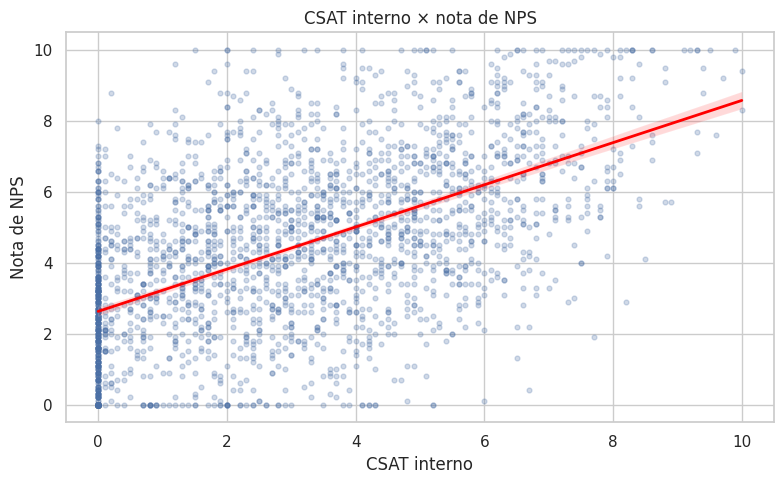

In [41]:
# ============================================================
# Célula 41 — CSAT interno × NPS: as duas notas contam a mesma história?
# ============================================================
print(f"Correlação de Spearman CSAT × NPS: {stats.spearmanr(df['csat_internal_score'], df['nps_score'])[0]:.2f}")

# O que move cada nota? Correlação de cada fator operacional com as duas notas
fatores = ["delivery_delay_days", "complaints_count", "customer_service_contacts", "resolution_time_days"]
comparacao = pd.DataFrame({
    "com NPS": df[fatores].corrwith(df["nps_score"], method="spearman"),
    "com CSAT": df[fatores].corrwith(df["csat_internal_score"], method="spearman"),
})
print(comparacao.round(2))
print(f"\nCSAT igual a zero: {(df['csat_internal_score'] == 0).sum()} pedidos "
      f"({(df['csat_internal_score'] == 0).mean():.1%})")

plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="csat_internal_score", y="nps_score",
            scatter_kws={"alpha": 0.25, "s": 12, "color": "#4A6FA5"}, line_kws={"color": "red", "lw": 2})
plt.title("CSAT interno × nota de NPS")
plt.xlabel("CSAT interno")
plt.ylabel("Nota de NPS")
plt.tight_layout()
plt.show()

### 📝 Análise dos resultados


- **As duas notas estão relacionadas, mas não são a mesma coisa.** A correlação é moderada (Spearman 0,56), e o gráfico mostra grande dispersão: para um mesmo CSAT, o NPS varia por quase toda a escala.
- **Cada nota reage a um fator diferente:**
  - o **NPS** é movido principalmente pelo **atraso** (−0,59) e pelas **reclamações** (−0,49);
  - o **CSAT** é movido principalmente pelo **tempo de resolução** (−0,74), que tem efeito pequeno no NPS (−0,19).
- **Interpretação:** o CSAT parece medir a **satisfação com o atendimento**, enquanto o NPS mede a **experiência completa**, dominada pela entrega.
- **H8 refutada:** o CSAT não substitui o NPS, mas é um indicador complementar útil para a área de atendimento.
- **Qualidade:** 462 pedidos (18,5%) têm CSAT exatamente 0, o mesmo efeito de corte na escala visto no NPS.

# 8. 🧪 Testes de hipótese

Os gráficos sugerem padrões; os testes dizem se esses padrões **superam o acaso**. Em todo teste comparamos duas ideias:

- **H₀ (hipótese nula):** nada mudou, não há diferença, não existe efeito.
- **H₁ (hipótese alternativa):** há diferença ou efeito.

Se o **p-valor < 0,05** (nível de significância α = 5%), os dados seriam muito improváveis caso H₀ fosse verdadeira: **rejeitamos H₀**. Se o p-valor for grande, **não rejeitamos H₀**.

### Como escolher o teste certo?

| Situação | Teste paramétrico (normalidade atendida) | Teste não paramétrico (sem normalidade) |
|---|---|---|
| Comparar 2 grupos independentes | Teste t independente | Mann-Whitney U |
| Comparar 3 ou mais grupos | ANOVA | Kruskal-Wallis |
| Relação entre duas numéricas | Pearson | Spearman |
| Duas categóricas | Qui-Quadrado (ou Fisher em tabelas 2×2 pequenas) | — |
| Comparar distribuições completas | — | Kolmogorov-Smirnov (KS) |

Primeiro verificamos a normalidade dos grupos; ela decide se os testes paramétricos são confiáveis.

In [42]:
# ============================================================
# Célula 42 — A nota é normal dentro dos grupos que vamos comparar?
# ============================================================
sem_atraso = df.loc[df["delivery_delay_days"] == 0, "nps_score"]
com_atraso = df.loc[df["delivery_delay_days"] > 0, "nps_score"]
sem_contato = df.loc[df["customer_service_contacts"] == 0, "nps_score"]
com_contato = df.loc[df["customer_service_contacts"] > 0, "nps_score"]

grupos = {"Sem atraso": sem_atraso, "Com atraso": com_atraso,
          "Sem contato com o SAC": sem_contato, "Com contato com o SAC": com_contato}
for regiao_nome, grupo in df.groupby("customer_region")["nps_score"]:
    grupos[f"Região {regiao_nome}"] = grupo

for nome, grupo in grupos.items():
    estatistica, p_valor = stats.shapiro(grupo)
    resultado = "normal (não rejeita H₀)" if p_valor > 0.05 else "NÃO normal (rejeita H₀)"
    print(f"{nome:25s} n = {len(grupo):4d} | W = {estatistica:.3f} | p-valor = {p_valor:.4f} → {resultado}")

Sem atraso                n =  277 | W = 0.974 | p-valor = 0.0001 → NÃO normal (rejeita H₀)
Com atraso                n = 2223 | W = 0.982 | p-valor = 0.0000 → NÃO normal (rejeita H₀)
Sem contato com o SAC     n =  554 | W = 0.986 | p-valor = 0.0000 → NÃO normal (rejeita H₀)
Com contato com o SAC     n = 1946 | W = 0.979 | p-valor = 0.0000 → NÃO normal (rejeita H₀)
Região Centro-Oeste       n =  468 | W = 0.973 | p-valor = 0.0000 → NÃO normal (rejeita H₀)
Região Nordeste           n =  485 | W = 0.984 | p-valor = 0.0000 → NÃO normal (rejeita H₀)
Região Norte              n =  506 | W = 0.980 | p-valor = 0.0000 → NÃO normal (rejeita H₀)
Região Sudeste            n =  520 | W = 0.982 | p-valor = 0.0000 → NÃO normal (rejeita H₀)
Região Sul                n =  521 | W = 0.982 | p-valor = 0.0000 → NÃO normal (rejeita H₀)


### 📝 Análise dos resultados


- **Todos os grupos rejeitam a normalidade** (p-valor < 0,05 no Shapiro-Wilk): com e sem atraso, com e sem contato com o SAC e as cinco regiões.
- **Decisão sobre os testes:**
  - Os testes **não paramétricos** (Mann-Whitney, Kruskal-Wallis, Spearman) são a referência, porque não supõem normalidade.
  - Os testes **paramétricos** (teste t, ANOVA) entram ao lado, como comparação. Com grupos grandes, o Teorema Central do Limite torna a comparação de médias razoável, e os dois tipos de teste devem concordar.

In [43]:
# ============================================================
# Célula 43 — H1: a nota é diferente entre pedidos com e sem atraso?
# ============================================================
# H₀: a nota é igual nos dois grupos | H₁: a nota é diferente

# Teste t independente (paramétrico): compara as MÉDIAS
t, p_valor = stats.ttest_ind(sem_atraso, com_atraso)
print("Teste t independente")
print(f"  médias: {sem_atraso.mean():.2f} (sem atraso) × {com_atraso.mean():.2f} (com atraso)")
print(f"  t = {t:.4f} | p-valor = {p_valor:.2e}")

# Mann-Whitney U (não paramétrico): compara os POSTOS (ranks), robusto a outliers e à falta de normalidade
u, p_valor = stats.mannwhitneyu(sem_atraso, com_atraso, alternative="two-sided")
print("\nMann-Whitney U")
print(f"  medianas: {sem_atraso.median():.1f} (sem atraso) × {com_atraso.median():.1f} (com atraso)")
print(f"  Estatística U = {u:.1f} | p-valor = {p_valor:.2e}")

# Kolmogorov-Smirnov: compara as DISTRIBUIÇÕES INTEIRAS (forma, caudas e dispersão)
ks, p_valor = stats.ks_2samp(sem_atraso, com_atraso)
print("\nKolmogorov-Smirnov")
print(f"  Estatística KS = {ks:.4f} | p-valor = {p_valor:.2e}")

if p_valor < 0.05:
    print("\n❗ Há evidência estatística de diferença significativa entre pedidos com e sem atraso (p < 0,05).")

Teste t independente
  médias: 6.86 (sem atraso) × 4.07 (com atraso)
  t = 18.5857 | p-valor = 2.53e-72

Mann-Whitney U
  medianas: 6.8 (sem atraso) × 4.1 (com atraso)
  Estatística U = 497578.5 | p-valor = 5.87e-63

Kolmogorov-Smirnov
  Estatística KS = 0.4636 | p-valor = 1.02e-48

❗ Há evidência estatística de diferença significativa entre pedidos com e sem atraso (p < 0,05).


### 📝 Análise dos resultados


- **Teste t independente:** médias de **6,86 (sem atraso) e 4,07 (com atraso)**; t = 18,59 e p-valor = 2,5 × 10⁻⁷².
- **Mann-Whitney U:** medianas de **6,8 e 4,1**; U = 497.578,5 e p-valor = 5,9 × 10⁻⁶³.
- **Kolmogorov-Smirnov:** KS = 0,46 e p-valor = 1,0 × 10⁻⁴⁸. As **distribuições inteiras** são diferentes, não só as médias.
- Os três testes concordam: **rejeitamos H₀**. **H1 está confirmada.**
- **Relevância prática:** uma diferença de cerca de **2,8 pontos de nota** é enorme numa escala de 0 a 10. Aqui a significância estatística vem acompanhada de significância prática.

In [44]:
# ============================================================
# Célula 44 — H2: a nota é diferente entre quem acionou e quem não acionou o SAC?
# ============================================================
t, p_t = stats.ttest_ind(sem_contato, com_contato)
u, p_u = stats.mannwhitneyu(sem_contato, com_contato, alternative="two-sided")

print(f"Sem contato: n = {len(sem_contato)} | média = {sem_contato.mean():.2f} | mediana = {sem_contato.median():.1f}")
print(f"Com contato: n = {len(com_contato)} | média = {com_contato.mean():.2f} | mediana = {com_contato.median():.1f}")
print(f"\nTeste t independente: t = {t:.4f} | p-valor = {p_t:.2e}")
print(f"Mann-Whitney U:       U = {u:.1f} | p-valor = {p_u:.2e}")
print("❗ Diferença estatisticamente significativa." if p_u < 0.05 else "Sem evidência de diferença.")

Sem contato: n = 554 | média = 5.54 | mediana = 5.5
Com contato: n = 1946 | média = 4.05 | mediana = 4.0

Teste t independente: t = 12.7758 | p-valor = 2.98e-36
Mann-Whitney U:       U = 718614.5 | p-valor = 4.41e-33
❗ Diferença estatisticamente significativa.


### 📝 Análise dos resultados


- Quem **não** acionou o SAC (554 pedidos) tem nota média de **5,54** (mediana 5,5). Quem acionou (1.946 pedidos) tem **4,05** (mediana 4,0).
- **Teste t:** p-valor = 3,0 × 10⁻³⁶. **Mann-Whitney U:** p-valor = 4,4 × 10⁻³³.
- **Rejeitamos H₀:** acionar o SAC está associado a uma nota cerca de **1,5 ponto menor**. **H2 está confirmada.**
- **Cuidado:** o contato com o SAC é, em geral, **sintoma** de um problema (como o atraso), e não necessariamente a causa da insatisfação.

In [45]:
# ============================================================
# Célula 45 — H5: a nota é diferente entre as regiões? (3 ou mais grupos)
# ============================================================
# H₀: as regiões têm a mesma nota | H₁: pelo menos uma região é diferente
notas_por_regiao = [grupo.values for _, grupo in df.groupby("customer_region")["nps_score"]]

# ANOVA (paramétrico): compara as médias de 3 ou mais grupos em um único passo
f_estatistico, p_anova = stats.f_oneway(*notas_por_regiao)
resultado_anova = {
    "F_estatistico": round(f_estatistico, 4),
    "p_valor": round(p_anova, 4),
    "grupos_analisados": sorted(df["customer_region"].unique()),
    "interpretacao": ("Há diferença estatística entre os grupos (p < 0,05)." if p_anova < 0.05
                      else "Não há diferença estatística entre os grupos (p >= 0,05)."),
}
print("ANOVA:", resultado_anova)

# Kruskal-Wallis (não paramétrico): equivalente à ANOVA sem supor normalidade
h, p_kw = stats.kruskal(*notas_por_regiao)
print(f"\nKruskal-Wallis: Estatística H = {h:.4f} | p-valor = {p_kw:.4f}")

ANOVA: {'F_estatistico': np.float64(0.8261), 'p_valor': np.float64(0.5083), 'grupos_analisados': ['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul'], 'interpretacao': 'Não há diferença estatística entre os grupos (p >= 0,05).'}

Kruskal-Wallis: Estatística H = 3.3787 | p-valor = 0.4966


### 📝 Análise dos resultados


- **ANOVA:** F = 0,83 e p-valor = 0,51. **Kruskal-Wallis:** H = 3,38 e p-valor = 0,50.
- Os dois testes concordam: **não rejeitamos H₀**. Não há evidência de diferença na nota entre as regiões. **H5 refutada.**
- O valor de F baixo indica que as médias das regiões são muito semelhantes em relação à variação dentro de cada região.
- **Erro Tipo II?** Não rejeitar H₀ não prova que as regiões são idênticas. Com cerca de 500 pedidos por região, porém, o teste tem poder para detectar diferenças de alguns décimos de ponto. Se houver diferença, ela é pequena demais para importar no negócio.

In [46]:
# ============================================================
# Célula 46 — H5: a categoria de NPS está associada à região? (Qui-Quadrado)
# ============================================================
# H₀: região e categoria de NPS são independentes | H₁: existe associação
tabela_observada = pd.crosstab(df["customer_region"], df["categoria_nps"])
qui2, p_valor, graus_liberdade, esperadas = stats.chi2_contingency(tabela_observada)

print(f"Qui-Quadrado: {qui2:.4f}")
print(f"p-valor: {p_valor:.4f}")
print(f"Graus de liberdade: {graus_liberdade}")
print("\nFrequências observadas:")
print(tabela_observada)
print("\nFrequências esperadas (se NÃO houvesse associação):")
print(pd.DataFrame(esperadas, index=tabela_observada.index, columns=tabela_observada.columns).round(1))

Qui-Quadrado: 3.5180
p-valor: 0.8978
Graus de liberdade: 8

Frequências observadas:
categoria_nps    Detrator  Neutro  Promotor
customer_region                            
Centro-Oeste          394      49        25
Nordeste              415      49        21
Norte                 431      57        18
Sudeste               435      62        23
Sul                   434      64        23

Frequências esperadas (se NÃO houvesse associação):
categoria_nps    Detrator  Neutro  Promotor
customer_region                            
Centro-Oeste      394.800  52.600    20.600
Nordeste          409.100  54.500    21.300
Norte             426.900  56.900    22.300
Sudeste           438.700  58.400    22.900
Sul               439.500  58.600    22.900


### 📝 Análise dos resultados


- **Qui-Quadrado = 3,52**, com **8 graus de liberdade** e **p-valor = 0,90**: **não rejeitamos H₀**. Região e categoria de NPS são independentes.
- As frequências **observadas** ficam muito próximas das **esperadas** (por exemplo: no Centro-Oeste, 394 detratores observados contra 394,8 esperados; no Sul, 64 neutros contra 58,6). É justamente essa proximidade que gera um χ² baixo.
- Todas as frequências esperadas são maiores que 5 (a menor é 20,6 promotores), então o teste qui-quadrado é adequado. O teste exato de Fisher só seria preferível em tabelas 2×2 com amostras pequenas.
- **H5 refutada** também pela ótica da composição de detratores, neutros e promotores.

In [47]:
# ============================================================
# Célula 47 — H1 a H4 e H6: correlação de Spearman de cada fator com a nota
# ============================================================
# H₀: não existe relação monotônica entre a variável e a nota | H₁: existe relação
linhas = []
for hipotese, coluna in [("H1", "delivery_delay_days"), ("H1", "delivery_time_days"),
                         ("H2", "customer_service_contacts"), ("H2", "complaints_count"),
                         ("H3", "resolution_time_days"), ("H4", "freight_value"),
                         ("H4", "discount_value"), ("H6", "customer_age"),
                         ("H6", "customer_tenure_months")]:
    rho, p_valor = stats.spearmanr(df[coluna], df["nps_score"])
    linhas.append({"hipótese": hipotese, "variável": coluna, "spearman (ρ)": round(rho, 3),
                   "p-valor": p_valor,
                   "rejeita H₀ (5%)?": "Sim" if p_valor < 0.05 else "Não"})

testes_spearman = pd.DataFrame(linhas)
testes_spearman["p-valor"] = testes_spearman["p-valor"].map(lambda v: f"{v:.1e}" if v < 0.001 else f"{v:.3f}")
testes_spearman

,hipótese,variável,spearman (ρ),p-valor,rejeita H₀ (5%)?
0,H1,delivery_delay_days,-0.586,1.1e-230,Sim
1,H1,delivery_time_days,0.000,0.988,Não
2,H2,customer_service_contacts,-0.336,3.4e-67,Sim
3,H2,complaints_count,-0.490,2.5e-151,Sim
4,H3,resolution_time_days,-0.190,8.0e-22,Sim
5,H4,freight_value,-0.040,0.048,Sim
6,H4,discount_value,0.012,0.563,Não
7,H6,customer_age,-0.007,0.710,Não
8,H6,customer_tenure_months,-0.012,0.560,Não


### 📝 Análise dos resultados


| Hipótese | Variável | ρ | Decisão |
|---|---|---|---|
| H1 | Atraso | −0,586 | ✅ Rejeita H₀ (p ≈ 10⁻²³⁰) |
| H1 | Tempo total de entrega | 0,000 | ❌ Não rejeita (p = 0,99) |
| H2 | Contatos com o SAC | −0,336 | ✅ Rejeita H₀ |
| H2 | Reclamações | −0,490 | ✅ Rejeita H₀ |
| H3 | Tempo de resolução | −0,190 | ✅ Rejeita H₀ (efeito moderado) |
| H4 | Frete | −0,040 | ⚠️ Rejeita H₀ por pouco (p = 0,048), efeito desprezível |
| H4 | Desconto | 0,012 | ❌ Não rejeita (p = 0,56) |
| H6 | Idade | −0,007 | ❌ Não rejeita (p = 0,71) |
| H6 | Tempo de relacionamento | −0,012 | ❌ Não rejeita (p = 0,56) |

**Significância estatística não é relevância prática.** Com 2.500 pedidos, até efeitos minúsculos podem dar p < 0,05. É o caso do frete: ρ = −0,04 significa que ele explica cerca de 0,2% da variação da nota.

**Erros Tipo I e Tipo II:**
- **Erro Tipo I (α = 5%):** rejeitar H₀ quando ela é verdadeira, ou seja, um falso positivo. Com 9 testes a 5%, a chance de pelo menos um falso positivo é alta. O resultado do frete, isolado e no limite (p = 0,048), é exatamente o tipo de achado que pode ser um **erro Tipo I**.
- **Erro Tipo II (β):** não rejeitar H₀ quando ela é falsa, ou seja, um falso negativo. Com 2.500 pedidos, o **poder (1 − β)** é alto para detectar correlações relevantes. As hipóteses refutadas (idade, tempo de relacionamento, desconto) indicam efeitos nulos ou desprezíveis.
- Os resultados de atraso, reclamações e contatos, com p-valores astronomicamente baixos, não correm risco de serem falsos positivos.

# 9. 🎲 Probabilidade condicional: como o risco de detrator muda quando sabemos algo sobre o pedido

A probabilidade condicional responde: *qual a chance de B acontecer, **dado que** A aconteceu?*

$$P(B \mid A) = \frac{P(A \cap B)}{P(A)}$$

Aqui, **A** = "o pedido atrasou 3 dias ou mais" e **B** = "o cliente é detrator".

In [48]:
# ============================================================
# Célula 48 — Probabilidade condicional, complementar e teste de independência
# ============================================================
# Evento A: pedido com 3 dias ou mais de atraso | Evento B: cliente detrator
P_A = (df["delivery_delay_days"] >= 3).mean()                 # probabilidade de atrasar 3+ dias
P_B = df["detrator"].mean()                                    # probabilidade de ser detrator

# Probabilidade conjunta: atrasou 3+ dias E é detrator
P_A_e_B = df[(df["delivery_delay_days"] >= 3) & (df["detrator"] == 1)].shape[0] / len(df)

# Probabilidade condicional: ser detrator DADO QUE atrasou 3+ dias
P_B_dado_A = P_A_e_B / P_A

# Para comparar: ser detrator dado que NÃO houve atraso nenhum (mesma fórmula)
P_sem_atraso = (df["delivery_delay_days"] == 0).mean()
P_sem_atraso_e_B = df[(df["delivery_delay_days"] == 0) & (df["detrator"] == 1)].shape[0] / len(df)
P_B_dado_sem_atraso = P_sem_atraso_e_B / P_sem_atraso

print(f"P(A)  atrasar 3+ dias:                    {P_A:.3f}")
print(f"P(B)  ser detrator:                       {P_B:.3f}")
print(f"P(A e B) atrasar 3+ dias E ser detrator:  {P_A_e_B:.3f}")
print(f"P(B | A) detrator dado atraso de 3+ dias: {P_B_dado_A:.3f}")
print(f"P(B | sem atraso):                        {P_B_dado_sem_atraso:.3f}")

# Probabilidade complementar: NÃO ser detrator dado atraso de 3+ dias
print(f"\nP(não detrator | A) = 1 − P(B | A) = {1 - P_B_dado_A:.3f}")

# Se A e B fossem independentes, valeria a regra da multiplicação: P(A e B) = P(A) × P(B)
print(f"\nSe fossem independentes: P(A) × P(B) = {P_A * P_B:.3f} | observado: P(A e B) = {P_A_e_B:.3f}")

P(A)  atrasar 3+ dias:                    0.385
P(B)  ser detrator:                       0.844
P(A e B) atrasar 3+ dias E ser detrator:  0.377
P(B | A) detrator dado atraso de 3+ dias: 0.980
P(B | sem atraso):                        0.516

P(não detrator | A) = 1 − P(B | A) = 0.020

Se fossem independentes: P(A) × P(B) = 0.325 | observado: P(A e B) = 0.377


### 📝 Análise dos resultados


- **P(A) = 0,385:** 38,5% dos pedidos atrasam 3 dias ou mais.
- **P(B) = 0,844:** 84,4% dos clientes são detratores.
- **P(A ∩ B) = 0,377:** 37,7% dos pedidos atrasam 3 ou mais dias **e** geram detratores.
- **P(B | A) = 0,377 / 0,385 = 0,980:** saber que o pedido atrasou 3 ou mais dias eleva a chance de detrator para **98,0%**. Sem atraso nenhum, a chance cai para **51,6%**.
- **Probabilidade complementar:** P(não detrator | A) = 1 − 0,980 = **0,020**. Só 2 em cada 100 clientes com 3 ou mais dias de atraso não viram detratores.
- **Independência:** se atraso e detrator fossem independentes, valeria a regra da multiplicação, P(A ∩ B) = P(A) × P(B) = 0,325. O valor observado é 0,377: os eventos **não são independentes**.
- **Leitura de negócio:** o risco de detrator é **previsível antes da pesquisa**. Um alerta simples ("pedido com 3 ou mais dias de atraso") identifica clientes que quase certamente serão detratores, a tempo de uma ação de recuperação.

# 10. 📐 Regressão linear múltipla exploratória

As correlações olham uma variável por vez. A **regressão linear múltipla** estima o efeito de cada variável **mantendo as demais constantes**, pelo método dos **mínimos quadrados ordinários (OLS)**: encontra os coeficientes que minimizam a soma dos quadrados dos resíduos.

Aqui ela é **exploratória**: serve para quantificar os achados da EDA (*quantos pontos de nota cada fator custa?*), e não como o modelo final, que terá separação em treino e teste nas próximas fases.

**Variáveis usadas:** apenas as registradas antes da pesquisa ou de momento incerto. Ficam de fora:
- `repeat_purchase_30d`: acontece **depois** da pesquisa (seria **vazamento de dados**);
- `csat_internal_score`: é outra medida de satisfação, não uma causa da nota.

In [49]:
# ============================================================
# Célula 49 — Ajustando a regressão linear múltipla com statsmodels (OLS)
# ============================================================
variaveis_x = antes_da_pesquisa + ["customer_service_contacts", "resolution_time_days", "complaints_count"]

# A região é categórica: viramos colunas 0/1 (Centro-Oeste fica como referência)
dummies_regiao = pd.get_dummies(df["customer_region"], prefix="regiao", drop_first=True, dtype=int)

# Variáveis independentes (X) com uma constante para o intercepto, e variável dependente (Y)
X = sm.add_constant(pd.concat([df[variaveis_x], dummies_regiao], axis=1))
Y = df["nps_score"]

# Cria e ajusta o modelo de regressão linear múltipla
modelo = sm.OLS(Y, X).fit()

# Imprime o resumo do modelo
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:              nps_score   R-squared:                       0.561
Model:                            OLS   Adj. R-squared:                  0.558
Method:                 Least Squares   F-statistic:                     186.8
Date:                Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:06:53   Log-Likelihood:                -4817.7
No. Observations:                2500   AIC:                             9671.
Df Residuals:                    2482   BIC:                             9776.
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

### 📝 Análise dos resultados


**Lendo o `summary()`:**

- **R-squared (R²) = 0,561** e R² ajustado = 0,558: o modelo explica cerca de **56% da variação da nota**.
- **Prob (F-statistic) ≈ 0,00:** o modelo como um todo é estatisticamente significativo.
- **Coeficientes significativos (P>|t| < 0,05) e relevantes**, todos negativos:

| Variável | coef | std err | P>\|t\| |
|---|---|---|---|
| Atraso na entrega | −0,955 | 0,024 | 0,000 |
| Reclamações | −0,374 | 0,030 | 0,000 |
| Contatos com o SAC | −0,328 | 0,043 | 0,000 |
| Tempo de resolução | −0,141 | 0,010 | 0,000 |

- **Não significativos (P>|t| > 0,05):** idade, tempo de relacionamento, itens, desconto, parcelas, **tempo total de entrega (p = 0,996)** e as regiões Nordeste, Norte e Sudeste.
- **Significativos, mas com efeito pequeno:** valor do pedido (+0,0004 por real), frete (−0,006 por real), tentativas de entrega (+0,09) e região Sul (+0,23 em relação ao Centro-Oeste). Com 17 coeficientes testados, alguns falsos positivos (erro Tipo I) são esperados, e os testes diretos de região não encontraram diferença.
- **Nota [2] do summary (condition number grande):** reflete principalmente as **escalas diferentes** das variáveis (valores em reais, na casa das centenas, ao lado de variáveis 0/1). A redundância real que conhecemos é entre contatos e reclamações (correlação de 0,75); por isso os efeitos individuais dessas duas devem ser lidos em conjunto.
- **Omnibus e Jarque-Bera** (p ≈ 0,10): os resíduos são compatíveis com uma distribuição normal (ver Célula 52).

In [50]:
# ============================================================
# Célula 50 — Métricas de avaliação: MAE, MSE, RMSE e R²
# ============================================================
# Realiza as previsões
y_pred = modelo.predict(X)

mae = mean_absolute_error(Y, y_pred)      # erro médio absoluto (mesma unidade da nota)
mse = mean_squared_error(Y, y_pred)       # erro quadrático médio (penaliza mais os erros grandes)
rmse = np.sqrt(mse)                       # raiz do MSE: volta para a escala da nota
r2 = r2_score(Y, y_pred)                  # proporção da variação da nota explicada pelo modelo

print(f"MAE  (Erro Médio Absoluto):           {mae:.2f} pontos de nota")
print(f"MSE  (Erro Quadrático Médio):         {mse:.2f}")
print(f"RMSE (Raiz do Erro Quadrático Médio): {rmse:.2f} pontos de nota")
print(f"R²   (Coeficiente de Determinação):   {r2:.3f} → o modelo explica {r2 * 100:.1f}% da variação da nota")

MAE  (Erro Médio Absoluto):           1.31 pontos de nota
MSE  (Erro Quadrático Médio):         2.76
RMSE (Raiz do Erro Quadrático Médio): 1.66 pontos de nota
R²   (Coeficiente de Determinação):   0.561 → o modelo explica 56.1% da variação da nota


### 📝 Análise dos resultados


- **MAE = 1,31:** em média, a previsão erra **1,3 ponto de nota** (na mesma unidade da nota).
- **MSE = 2,76:** penaliza mais os erros grandes; não está na mesma escala da nota.
- **RMSE = 1,66:** volta para a escala da nota; os erros típicos ficam em torno de **1,7 ponto**.
- **R² = 0,561:** o modelo explica **56,1%** da variação da nota.
- **Leitura de negócio:** um erro de ±1,3 a 1,7 ponto é grande perto da fronteira de detrator (7). Um cliente previsto com nota 7,5 pode, na verdade, ter dado 6,2. Isso reforça a ideia de, na próxima fase, também tratar o problema como **classificação** (detrator: sim ou não).
- **Cuidado:** estas métricas foram calculadas **nos mesmos dados usados para ajustar o modelo** (sem separação em treino e teste), então são otimistas. O modelo final precisará de divisão treino/teste.

In [51]:
# ============================================================
# Célula 51 — Interpretando os coeficientes
# ============================================================
coef_df = pd.DataFrame({
    "coeficiente": modelo.params,
    "p-valor": modelo.pvalues,
})
coef_df["significativo (5%)?"] = np.where(coef_df["p-valor"] < 0.05, "Sim", "Não")

# Efeito de uma variação típica (1 desvio padrão): coloca variáveis de escalas diferentes na mesma régua
desvios = X.drop(columns="const").std()
coef_df["efeito_1_desvio_padrao"] = coef_df["coeficiente"] * desvios
coef_df = coef_df.drop(index="const").sort_values("efeito_1_desvio_padrao")
print(f"Intercepto (nota esperada com todas as variáveis em zero): {modelo.params['const']:.2f}")
coef_df.round(4)

Intercepto (nota esperada com todas as variáveis em zero): 9.01


,coeficiente,p-valor,significativo (5%)?,efeito_1_desvio_padrao
delivery_delay_days,-0.955,0.000,Sim,-1.389
complaints_count,-0.374,0.000,Sim,-0.668
resolution_time_days,-0.141,0.000,Sim,-0.487
customer_service_contacts,-0.328,0.000,Sim,-0.404
freight_value,-0.006,0.023,Sim,-0.076
customer_tenure_months,-0.001,0.284,Não,-0.036
discount_value,-0.000,0.781,Não,-0.009
customer_age,-0.000,0.911,Não,-0.004
delivery_time_days,0.000,0.996,Não,0.000
items_quantity,0.016,0.424,Não,0.027


### 📝 Análise dos resultados


**Interpretando os coeficientes (mantendo as demais variáveis constantes):**

- **Atraso:** para cada dia a mais de atraso, a nota **cai em média 0,95 ponto**. Três dias de atraso custam cerca de **2,9 pontos**.
- **Reclamações:** cada reclamação a mais tira **0,37 ponto**.
- **Contatos com o SAC:** cada contato a mais tira **0,33 ponto**.
- **Tempo de resolução:** cada dia de espera tira **0,14 ponto** (até 11 dias, isso soma mais de 1,5 ponto).

**Comparando na mesma régua (efeito de uma variação típica de 1 desvio padrão):**

| Fator | Efeito na nota |
|---|---|
| Atraso | **−1,39 ponto** |
| Reclamações | −0,67 ponto |
| Tempo de resolução | −0,49 ponto |
| Contatos com o SAC | −0,40 ponto |
| Todas as demais | no máximo ±0,11 ponto |

- O **atraso pesa mais que o dobro** do segundo fator.
- **Intercepto (9,01):** é a nota prevista com todas as variáveis em zero. Na prática, essa combinação não existe (ninguém tem 0 anos de idade), então não extrapolamos o intercepto para fora da faixa dos dados. Ele indica que, **sem nenhum problema na jornada, a nota esperada fica perto de 9** (zona de promotor), e que **2 a 3 dias de atraso bastam para levar o cliente abaixo de 7**.

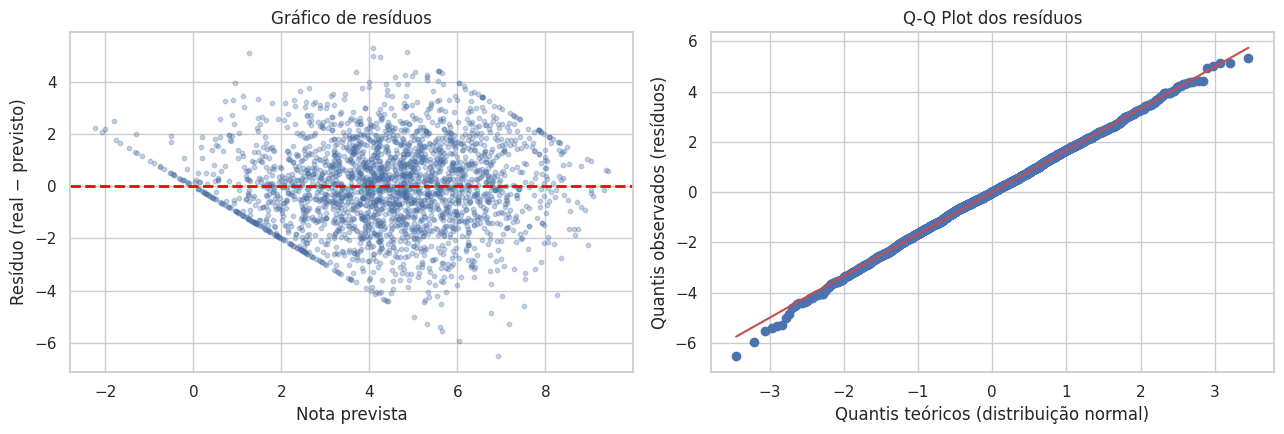

Média dos resíduos: 0.0000
Shapiro-Wilk nos resíduos: W = 0.9991 | p-valor = 0.2516 → resíduos normais (p > 0,05)
Previsões abaixo de 0 (fora da escala da nota): 33


In [52]:
# ============================================================
# Célula 52 — Verificando os pressupostos: resíduos
# ============================================================
residuos = Y - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Resíduos × valores previstos: o ideal é uma nuvem sem padrão em torno do zero
axes[0].scatter(y_pred, residuos, alpha=0.3, s=10, color="#4A6FA5")
axes[0].axhline(y=0, color="red", linestyle="--", linewidth=2)
axes[0].set_title("Gráfico de resíduos")
axes[0].set_xlabel("Nota prevista")
axes[0].set_ylabel("Resíduo (real − previsto)")

# Q-Q plot dos resíduos: os pontos devem acompanhar a reta se os resíduos forem normais
stats.probplot(residuos, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot dos resíduos")
axes[1].set_xlabel("Quantis teóricos (distribuição normal)")
axes[1].set_ylabel("Quantis observados (resíduos)")
plt.tight_layout()
plt.show()

print(f"Média dos resíduos: {residuos.mean():.4f}")
estatistica, p_valor = stats.shapiro(residuos)
print(f"Shapiro-Wilk nos resíduos: W = {estatistica:.4f} | p-valor = {p_valor:.4f} → "
      f"{'resíduos normais (p > 0,05)' if p_valor > 0.05 else 'resíduos NÃO normais'}")
print(f"Previsões abaixo de 0 (fora da escala da nota): {(y_pred < 0).sum()}")

### 📝 Análise dos resultados


- **Média dos resíduos ≈ 0** e **Shapiro-Wilk nos resíduos com p-valor = 0,25** (resíduos normais). O **QQ-plot** acompanha a reta: os pressupostos de normalidade e de resíduos centrados em zero estão atendidos.
- **Mas o gráfico de resíduos mostra uma linha diagonal** no canto inferior esquerdo. São as notas **iguais a 0**: quando a nota real é 0, o resíduo é exatamente "−previsto". Além disso, **33 previsões ficaram abaixo de 0**, um valor impossível na escala.
- **Limitação do modelo linear:** a reta não respeita os limites de 0 a 10. Para a modelagem final, vale considerar abordagens que respeitem a escala, como **classificar detratores** (sim ou não).
- **Leitura crítica:** resíduos tão "perfeitamente normais" são raros em dados reais de satisfação. É mais um indício de base simulada.

# 11. 📝 Registro das descobertas e hipóteses

### 11.1 Registro estruturado: Observação → Evidência → Hipótese associada → Próximos passos

| # | Observação | Evidência | Hipótese associada | Próximos passos |
|---|---|---|---|---|
| 1 | O NPS é extremamente negativo | NPS = −80 (IC 95%: −81,8 a −78,0); 84,4% de detratores; −74 com outra regra de corte | O problema é estrutural, não uma flutuação | Comparar com benchmarks do setor e acompanhar ao longo do tempo |
| 2 | **O atraso é o principal fator** | Spearman −0,59; −0,95 ponto por dia; P(detrator \| atraso ≥ 3) = 98% | A quebra da promessa de prazo gera detratores | Investigar as causas do atraso (transportadora, CD, rota); testar ação proativa (A/B) |
| 3 | O tempo total de entrega não importa | Spearman 0,000; nota estável entre 4,19 e 4,69 | O cliente pune o prazo descumprido, não o prazo longo | Revisar a promessa de prazo no checkout |
| 4 | Há pontos de ruptura | Detratores: 52% → 74% no 1º dia de atraso; ≥ 97% a partir do 3º; 30% → 65% na 2ª reclamação | Existe uma janela de ação antes do 1º dia e antes da 2ª reclamação | Criar alertas nesses momentos |
| 5 | Reclamações e contatos derrubam a nota | Spearman −0,49 e −0,34; NPS +22 sem reclamação | O volume de problemas pesa mais que a velocidade de resolução | Confirmar se esses registros são anteriores à pesquisa |
| 6 | Preço, perfil e região não importam | \|ρ\| ≤ 0,04; ANOVA, Kruskal-Wallis e qui-quadrado com p ≥ 0,50 | O problema é operacional e nacional | Não usar desconto ou segmentação por perfil como alavanca de NPS |
| 7 | A recompra é função exata da nota | 100% de recompra com nota ≥ 8; 0% abaixo de 8 | A coluna foi derivada da nota (vazamento) | Validar a origem da coluna; não usá-la como explicativa |
| 8 | O CSAT mede o atendimento | Spearman CSAT × resolução = −0,74; CSAT × NPS = 0,56 | São indicadores complementares | Usar o CSAT como indicador da área de atendimento |
| 9 | A base tem sinais de simulação | Distribuições uniformes e de Poisson quase perfeitas; notas decimais; resíduos normais | Os padrões refletem as regras de geração | Cautela ao generalizar para o comportamento real |

### 11.2 Status das hipóteses

| Hipótese | Status |
|---|---|
| H1 — O atraso reduz a nota | ✅ **Confirmada** (efeito forte) |
| H2 — Contatos e reclamações reduzem a nota | ✅ **Confirmada** (efeito moderado a forte) |
| H3 — Resolução lenta reduz a nota | ✅ Confirmada (efeito moderado) |
| H4 — Frete e desconto afetam a nota | ❌ Sem efeito prático |
| H5 — A nota difere entre regiões | ❌ Refutada |
| H6 — O perfil do cliente influencia a nota | ❌ Refutada |
| H7 — Nota alta → mais recompra | ⚠️ Inconclusiva (relação determinística, artefato da base) |
| H8 — CSAT e NPS medem o mesmo | ❌ Refutada (medem coisas diferentes) |

### 11.3 O que já sabemos e o que ainda precisa ser verificado

- **Já sabemos:** o atraso, as reclamações e os contatos com o SAC estão fortemente associados às notas baixas; preço, perfil e região não estão.
- **Precisa ser verificado com o negócio:**
  - em que momento a pesquisa é disparada;
  - se reclamações e contatos são registrados antes ou depois da pesquisa;
  - por que a nota tem casas decimais;
  - como a coluna de recompra foi gerada;
  - qual é a definição de `delivery_time_days`.
- **Precisa ser verificado com experimento:** se reduzir o atraso ou avisar o cliente **causa** a melhora da nota (teste A/B, Seção 13).

# 12. 📖 Storytelling: contando a história com os dados

### 12.1 Elementos da narrativa

- **Pergunta:** quais pontos da jornada transformam clientes em detratores?
- **Contexto:** em um e-commerce, trocar de loja custa um clique. O que segura o cliente é a experiência: entrega, atendimento e pós-venda. A empresa mede essa experiência com o NPS.
- **Evidências:** NPS de −80; nota caindo cerca de 1 ponto por dia de atraso; pontos de ruptura no 1º e no 3º dia de atraso e na 2ª reclamação; nenhuma diferença por preço, perfil ou região.
- **Conclusão:** o vilão é a **promessa de prazo quebrada**, agravada pelas reclamações.

### 12.2 A história em três atos (E / MAS / PORTANTO)

- **E (contexto):** o e-commerce tem um NPS de **−80**. Para cada cliente que recomenda a loja, existem 19 que falariam mal dela, em todas as regiões e em todos os perfis de cliente.
- **MAS (conflito):** o problema não é preço, frete nem público. **É o prazo descumprido.** 89% dos pedidos atrasam, e cada dia de atraso custa quase 1 ponto de nota. A partir de 3 dias de atraso, 98% dos clientes viram detratores. Reclamações e contatos com o SAC agravam o quadro.
- **PORTANTO (resolução):** a principal alavanca está na **logística e na promessa de prazo**, apoiada pelo **atendimento**. Como o risco de detrator é previsível antes da pesquisa, a empresa pode agir **durante** a jornada, e não só depois da nota.

### 12.3 Pergunta → Descoberta → Insight → Recomendação

| Pergunta | Descoberta | Insight | Recomendação |
|---|---|---|---|
| O que mais gera detratores? | Atraso: de 52% (sem atraso) para 97% ou mais de detratores (3+ dias) | A promessa quebrada pesa mais do que o prazo longo | Meta de entrega no prazo por transportadora e CD; prometer no checkout só prazos que se cumprem |
| Quando agir? | Maior queda no 1º dia de atraso e na 2ª reclamação | Existe uma janela curta de prevenção | Aviso proativo ao cliente no 1º dia de atraso, com novo prazo |
| Quem recuperar? | P(detrator \| atraso ≥ 3 dias) = 98% | Esses clientes já estão praticamente perdidos | Régua de recuperação para pedidos com 3+ dias de atraso ou 2+ reclamações |
| O preço importa? | Frete, desconto e valor sem efeito | O problema é operacional | Não usar descontos para tentar mover o NPS |

### 12.4 Cuidados para contar esta história com honestidade

- **Não forçar causalidade:** os dados mostram associações. O teste A/B é que comprova o efeito de uma ação.
- **Reconhecer as limitações:** a base tem sinais de simulação, não tem datas, só inclui quem respondeu e tem colunas de momento incerto.
- **Não extrapolar:** o efeito real no mundo tende a ser menor e mais ruidoso do que nesta base.

# 13. 🧪 Próximo passo: desenho de um teste A/B

A EDA mostra **associações**. Para saber se uma ação **causa** a redução de detratores, o caminho é um experimento controlado. Proposta:

- **Problema e objetivo:** avisar proativamente o cliente quando o pedido atrasa (com novo prazo) reduz a proporção de detratores?
- **População alvo:** pedidos que atrasaram.
- **Métrica primária:** % de detratores. **Métricas secundárias:** nota média, CSAT e número de reclamações (para detectar efeitos colaterais).
- **Hipóteses:** H₀: a % de detratores é igual nos grupos A (processo atual) e B (aviso proativo) | H₁: a % é diferente. Usamos o teste **bilateral**, porque um aviso mal feito também poderia piorar a experiência.
- **Efeito mínimo detectável (MDE):** redução de 5 pontos percentuais.
- **Nível de significância α = 5%** (risco de erro Tipo I) e **poder = 80%** (1 − β; risco de erro Tipo II de 20%).

In [53]:
# ============================================================
# Célula 53 — Tamanho de amostra necessário para o teste A/B
# ============================================================
# Taxa base: % de detratores hoje entre os pedidos com atraso
taxa_base = df.loc[df["delivery_delay_days"] > 0, "detrator"].mean()
mde = 0.05                                   # efeito mínimo detectável: −5 pontos percentuais
taxa_esperada = taxa_base - mde

# Tamanho do efeito para duas proporções e cálculo do tamanho de amostra por grupo
efeito = proportion_effectsize(taxa_base, taxa_esperada)
n_por_grupo = NormalIndPower().solve_power(effect_size=efeito, alpha=0.05, power=0.80,
                                           alternative="two-sided")

print(f"Taxa base de detratores (pedidos atrasados): {taxa_base:.1%}")
print(f"Taxa esperada com o aviso proativo:          {taxa_esperada:.1%}")
print(f"Pedidos atrasados necessários por grupo:     {np.ceil(n_por_grupo):.0f}")
print(f"Total do experimento (A + B):                {2 * np.ceil(n_por_grupo):.0f}")
print(f"Pedidos atrasados nesta base, para referência: {(df['delivery_delay_days'] > 0).sum()}")

Taxa base de detratores (pedidos atrasados): 88.4%
Taxa esperada com o aviso proativo:          83.4%
Pedidos atrasados necessários por grupo:     754
Total do experimento (A + B):                1508
Pedidos atrasados nesta base, para referência: 2223


### 📝 Análise dos resultados


- **Taxa base:** hoje, **88,4%** dos pedidos atrasados geram detratores. A meta é detectar uma redução de pelo menos 5 pontos percentuais, para **83,4%**.
- **Tamanho de amostra:** são necessários **754 pedidos atrasados por grupo**, 1.508 no total, com:
  - **α = 5%:** risco de concluir que o aviso funciona quando não funciona (erro Tipo I, falso positivo);
  - **poder de 80%:** 20% de risco de não detectar um efeito que existe (erro Tipo II, falso negativo).
- **Viabilidade:** como 89% dos pedidos atrasam (2.223 nesta base), a amostra é atingida rapidamente.

**Próximos passos do desenho do experimento:**
1. **Aleatorização:** sortear cada pedido atrasado para o grupo A ou B, na proporção 1:1. A unidade experimental é o pedido.
2. **Janela de observação:** pelo menos algumas semanas completas, evitando datas atípicas (Black Friday, Natal), sem encerrar o teste antes do tamanho de amostra planejado.
3. **Análise:** teste de proporções (estatística Z) ou qui-quadrado na % de detratores, com o intervalo de confiança da diferença entre os grupos e as métricas secundárias.
4. **Decisão de negócio:** se a redução for estatisticamente **e** praticamente relevante, expandir o aviso para toda a operação de forma gradual (rollout), monitorando os resultados.